# Emitting Patterns 2D Projection

This tutorial shows how to visualise the hot emitting regions of an X-PSI model on the stellar surface with `plot_projection_filled`.

The function draws the star as a wireframe sphere (a latitude/longitude grid, 15° spacing by default) and colours every part of the surface that emits, with a colour set by its temperature. Masking is taken into account, so you see the shape that actually emits:

* **ST**: a single-temperature circular region.
* **CST / EST / PST**: a single-temperature region partly masked by a zero-temperature *omission* region. Only the part that is not masked is coloured, which can give rings, crescents or arcs.
* **CDT / EDT / PDT**: two emitting regions at different temperatures. The *superseding* region masks the part of the *ceding* region it overlaps.

The projection is orthographic: **no gravitational light bending is included**. It shows where the hot regions are on the surface and what shape they have, not what an observer would actually see.

Emission on the hemisphere facing the viewer is drawn solid. Emission on the far hemisphere, seen through the star, is drawn with diagonal hatching and a dashed outline. The poles are marked with ★ and the point at phase 0 on the equator with ○.

The function lives in `xpsi/utilities/ProjectionToolFilled.py`. It only needs numpy, scipy and matplotlib, so <b>you can also use this file without X-PSI installed</b>.

In [1]:
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

# store the inline figures as JPEG: the smooth background and glow make PNG files large
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 90}}

If you installed X-PSI, run the code below

In [2]:
from xpsi.utilities.ProjectionToolFilled import plot_projection_filled, animate_projection_filled, HOT_GLOW_CMAP

In [3]:
# Else uncomment the lines below (the path is relative to docs/source in your local clone of the X-PSI repository)
#!ln -s ../../xpsi/utilities/ProjectionToolFilled.py .
#from ProjectionToolFilled import plot_projection_filled, animate_projection_filled, HOT_GLOW_CMAP

## Inputs

`plot_projection_filled` needs three arguments.

**Parameter values** `dictVp` [dict]: a dictionary of parameter values, or an X-PSI likelihood object / parameter subspace (see the [Modeling tutorial](https://xpsi-group.github.io/xpsi/Modeling.html)). Parameters use the usual X-PSI names, such as `p__super_colatitude`, `s__omit_radius` or `cos_inclination`. Parameters the tool doesn't need, such as mass or radius, are ignored.

**Model** `model` [str]: describes the hot regions. Each hot region is named with the X-PSI convention: `ST`, `CST`, `EST`, `PST`, `CDT`, `EDT` or `PDT`. The parameters of the primary region start with `p__` and those of the secondary with `s__`.
<ul>
  <li>One hot region: just its name, e.g. `"PST"`.</li>
  <li>Two hot regions of different types: join the names with `+`, primary first, e.g. `"ST+PDT"` or `"PDT+PST"`.</li>
  <li>Two hot regions of the same type, with a suffix:
    <ul>
      <li>`-S`: the secondary is antipodal to the primary, with the same angular radii and temperatures (no `s__` parameters needed);</li>
      <li>`-Ua`: the secondary is antipodal to the primary, but its angular radii and temperatures are free (`s__super_radius`, `s__super_temperature`, ...);</li>
      <li>`-U`: the two hot regions are completely independent (equivalent to e.g. `"ST+ST"`).</li>
    </ul></li>
</ul>

**Point of view** `POV`: the point on the surface at the centre of the image, i.e. the direction the star is viewed from. It can be:
<ul>
  <li>`"I"`: the observer's direction, at colatitude `arccos(cos_inclination)` and phase 0;</li>
  <li>the centre of one component: `"P"` / `"S"` for a single-component primary/secondary; `"PE"`/`"PO"` for the emitting/omitting component of a primary with an omission region; `"PS"`/`"PC"` for the superseding/ceding component of a double-temperature primary; and the same with `S` for the secondary. If you pass an option the model doesn't allow, the error message lists the ones it does;</li>
  <li>a 3-vector pointing from the centre of the star to the viewer, e.g. `[0, 0, 1]` for the north pole (normalised automatically);</li>
  <li>`""` (default): the north pole.</li>
</ul>

Optional arguments:
<ul>
  <li>**back_view** [bool]: add a second panel showing the star from the opposite side, as if you walked around it (north stays up). Emission on the far side of the main view appears there solid and undistorted.</li>
  <li>**Tmin, Tmax** [float]: limits of the log10(T [K]) colour scale. By default these are set from the model's temperatures, with a minimum width of `min_span` (default 0.3 dex) so that small temperature differences are not exaggerated. Fix them to compare several figures on the same scale.</li>
  <li>**cmap**: the colormap. The default is `inferno`; in the dark style its darkest 20% is left out, so cool regions stay visible against the background. Any matplotlib colormap works, and `HOT_GLOW_CMAP` (orange → magenta) is also provided.</li>
  <li>**style** [str]: `"dark"` (default) or `"light"` (e.g. for papers).</li>
  <li>**show_outlines** [bool]: also draw the outline of every component, with omission regions dashed, to see what is masking what.</li>
  <li>**show_far_side**, **far_style**, **far_alpha**, **far_legend**: how emission on the far hemisphere is drawn. With `far_style="hatch"` (default) it is hatched with a dashed outline; `"dim"` just dims it; `show_far_side=False` hides it. `far_legend` turns the near/far legend on or off.</li>
  <li>**antiphase** [bool]: the secondary's phase is defined from an origin half a cycle away from the primary's (default False).</li>
  <li>**antipodal** [bool]: also draw (dash-dotted) where a region antipodal to the primary would be (default False).</li>
  <li>**glow**, **grid_step** (wireframe spacing in degrees), **resolution** (pixels across the star), **colorbar**, **figsize**, **ax** (draw into existing axes).</li>
  <li>**SaveFlag**, **dir**, **Name**, **POVname**, **extension**: save the figure as `<dir>/ProjectionFilled_from_<POV>_<Name><extension>`. If POV is a vector, give `POVname` to use in the file name.</li>
</ul>
The function returns the matplotlib axes, or a tuple `(front, back)` when `back_view=True`.

## 1) One hot region
### 1.1) Single temperature (ST)

In [4]:
labels_1hs = ['mass',                 # not used for the projection
              'radius',               # not used for the projection
              'cos_inclination',
              'p__phase_shift',
              'p__super_colatitude',
              'p__super_radius',
              'p__super_temperature',
              'beta',                 # not used for the projection
              'column_density']       # not used for the projection

values_1hs = [1.2, 11, 0.8, 0.6, 1.9, 0.08, 6.1, 9.3, 0.8]

P_dictionary_1hs = dict(zip(labels_1hs, values_1hs))
P_dictionary_1hs

{'mass': 1.2,
 'radius': 11,
 'cos_inclination': 0.8,
 'p__phase_shift': 0.6,
 'p__super_colatitude': 1.9,
 'p__super_radius': 0.08,
 'p__super_temperature': 6.1,
 'beta': 9.3,
 'column_density': 0.8}

Seen from Earth (`POV="I"`), the hot spot is on the far hemisphere, so it is drawn hatched:

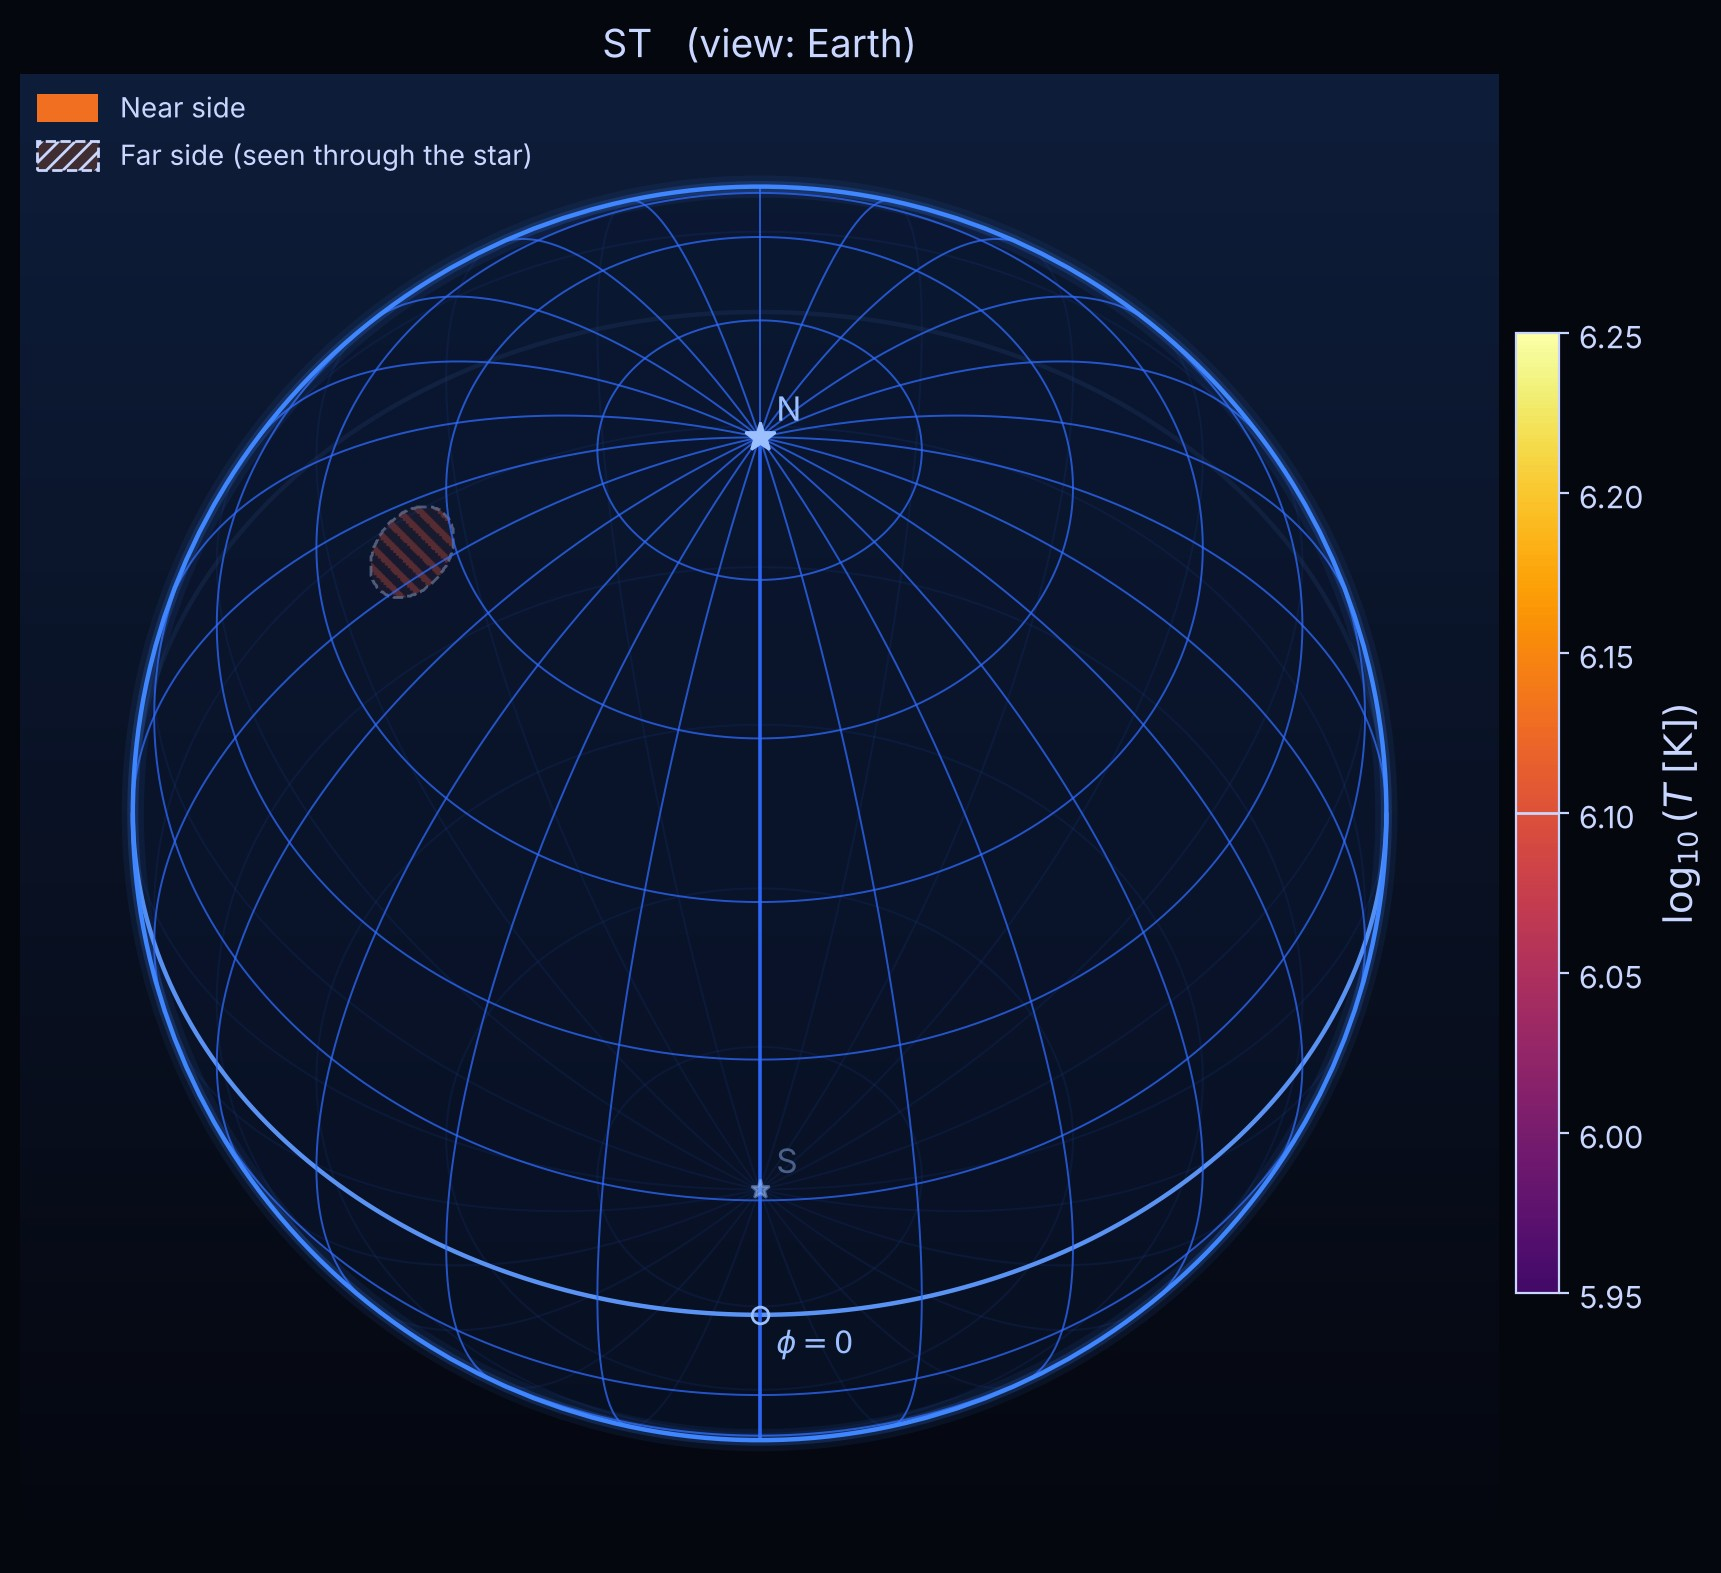

In [5]:
plot_projection_filled(P_dictionary_1hs, "ST", "I");

With `back_view=True`, a second panel shows the star from the opposite side, where the spot appears solid:

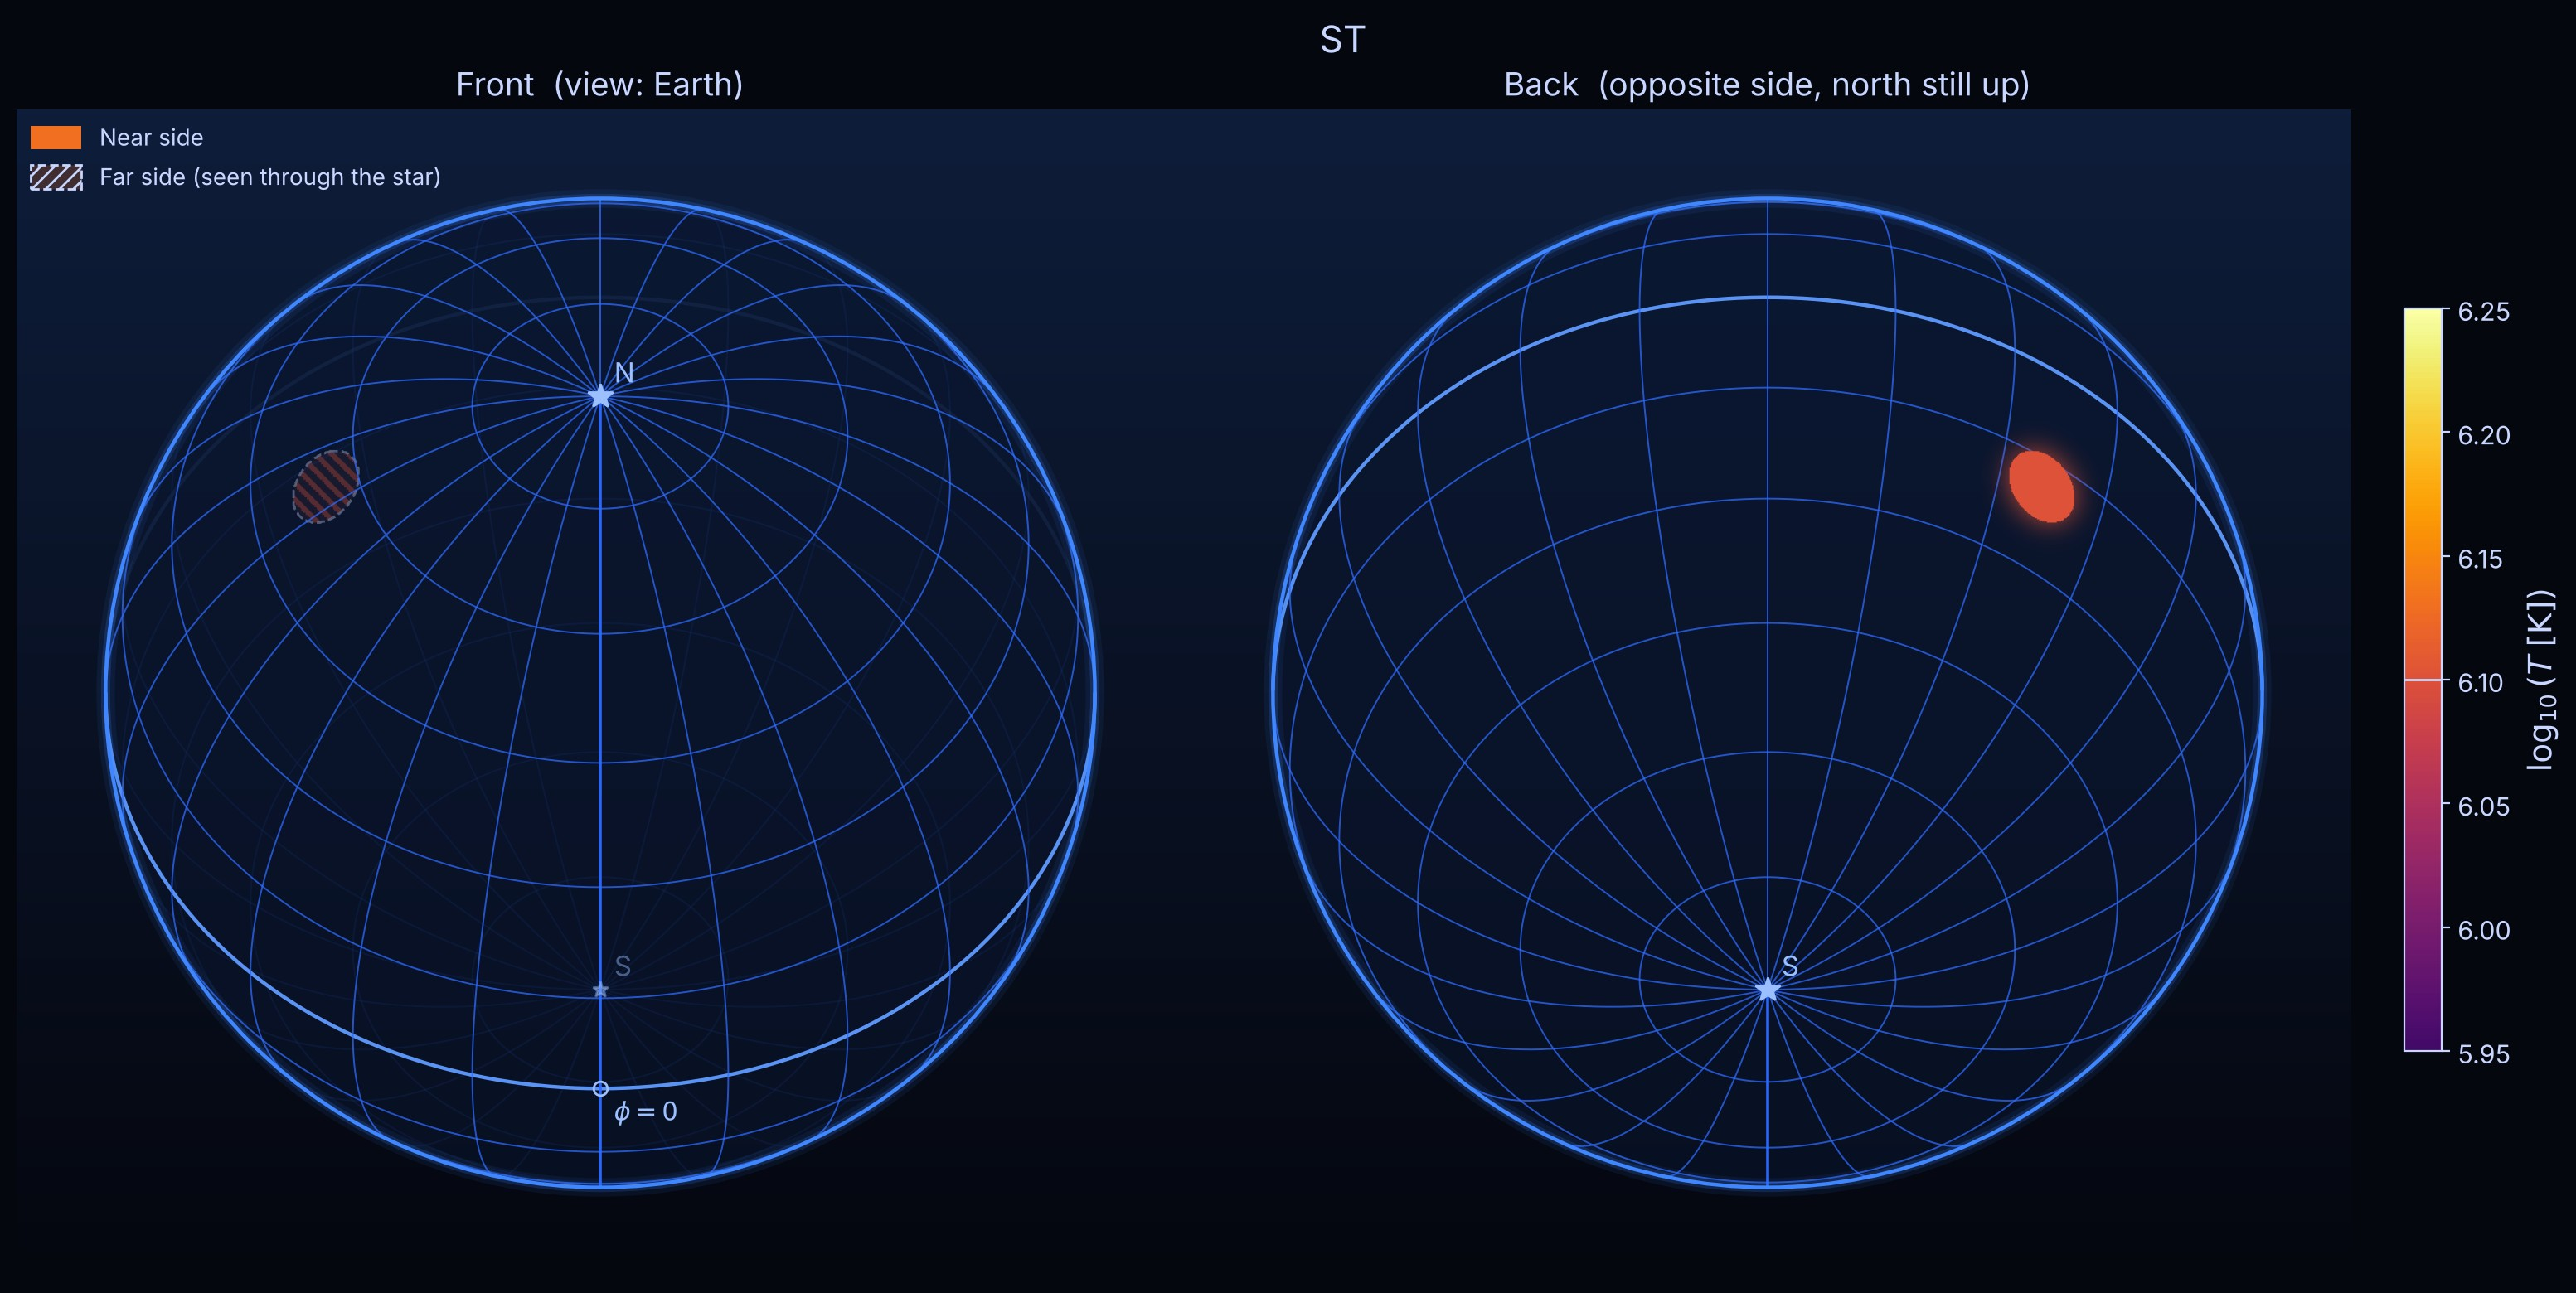

In [6]:
plot_projection_filled(P_dictionary_1hs, "ST", "I", back_view=True);

Or centre the projection on the hot spot itself:

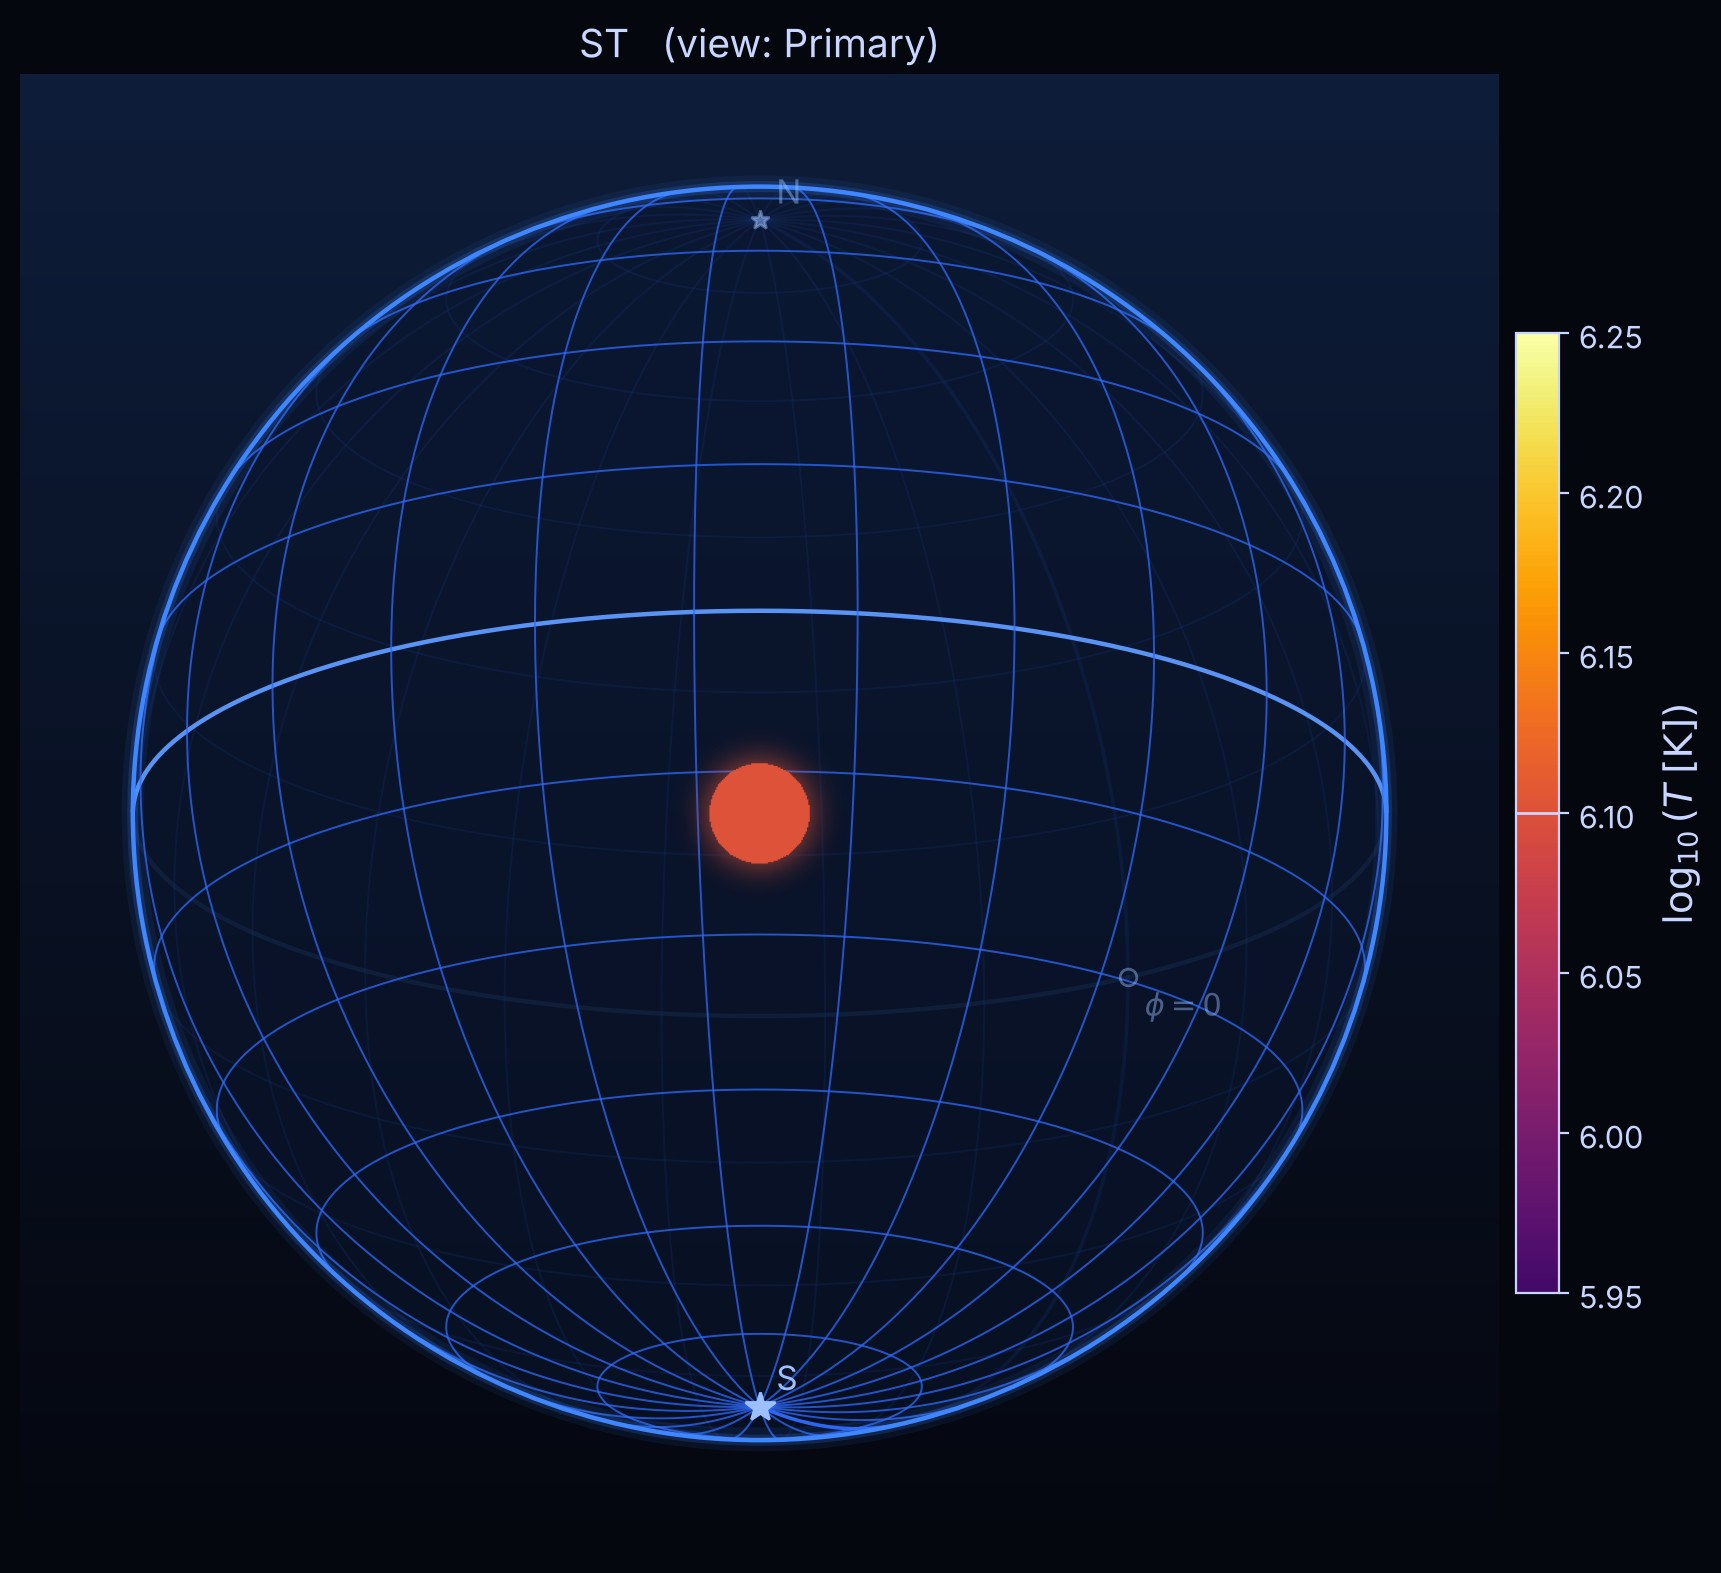

In [7]:
plot_projection_filled(P_dictionary_1hs, "ST", "P");

### 1.2) Two temperatures (PDT, CDT)
In a double-temperature hot region the superseding component masks the part of the ceding component it overlaps. With `show_outlines=True` you can see both full components.

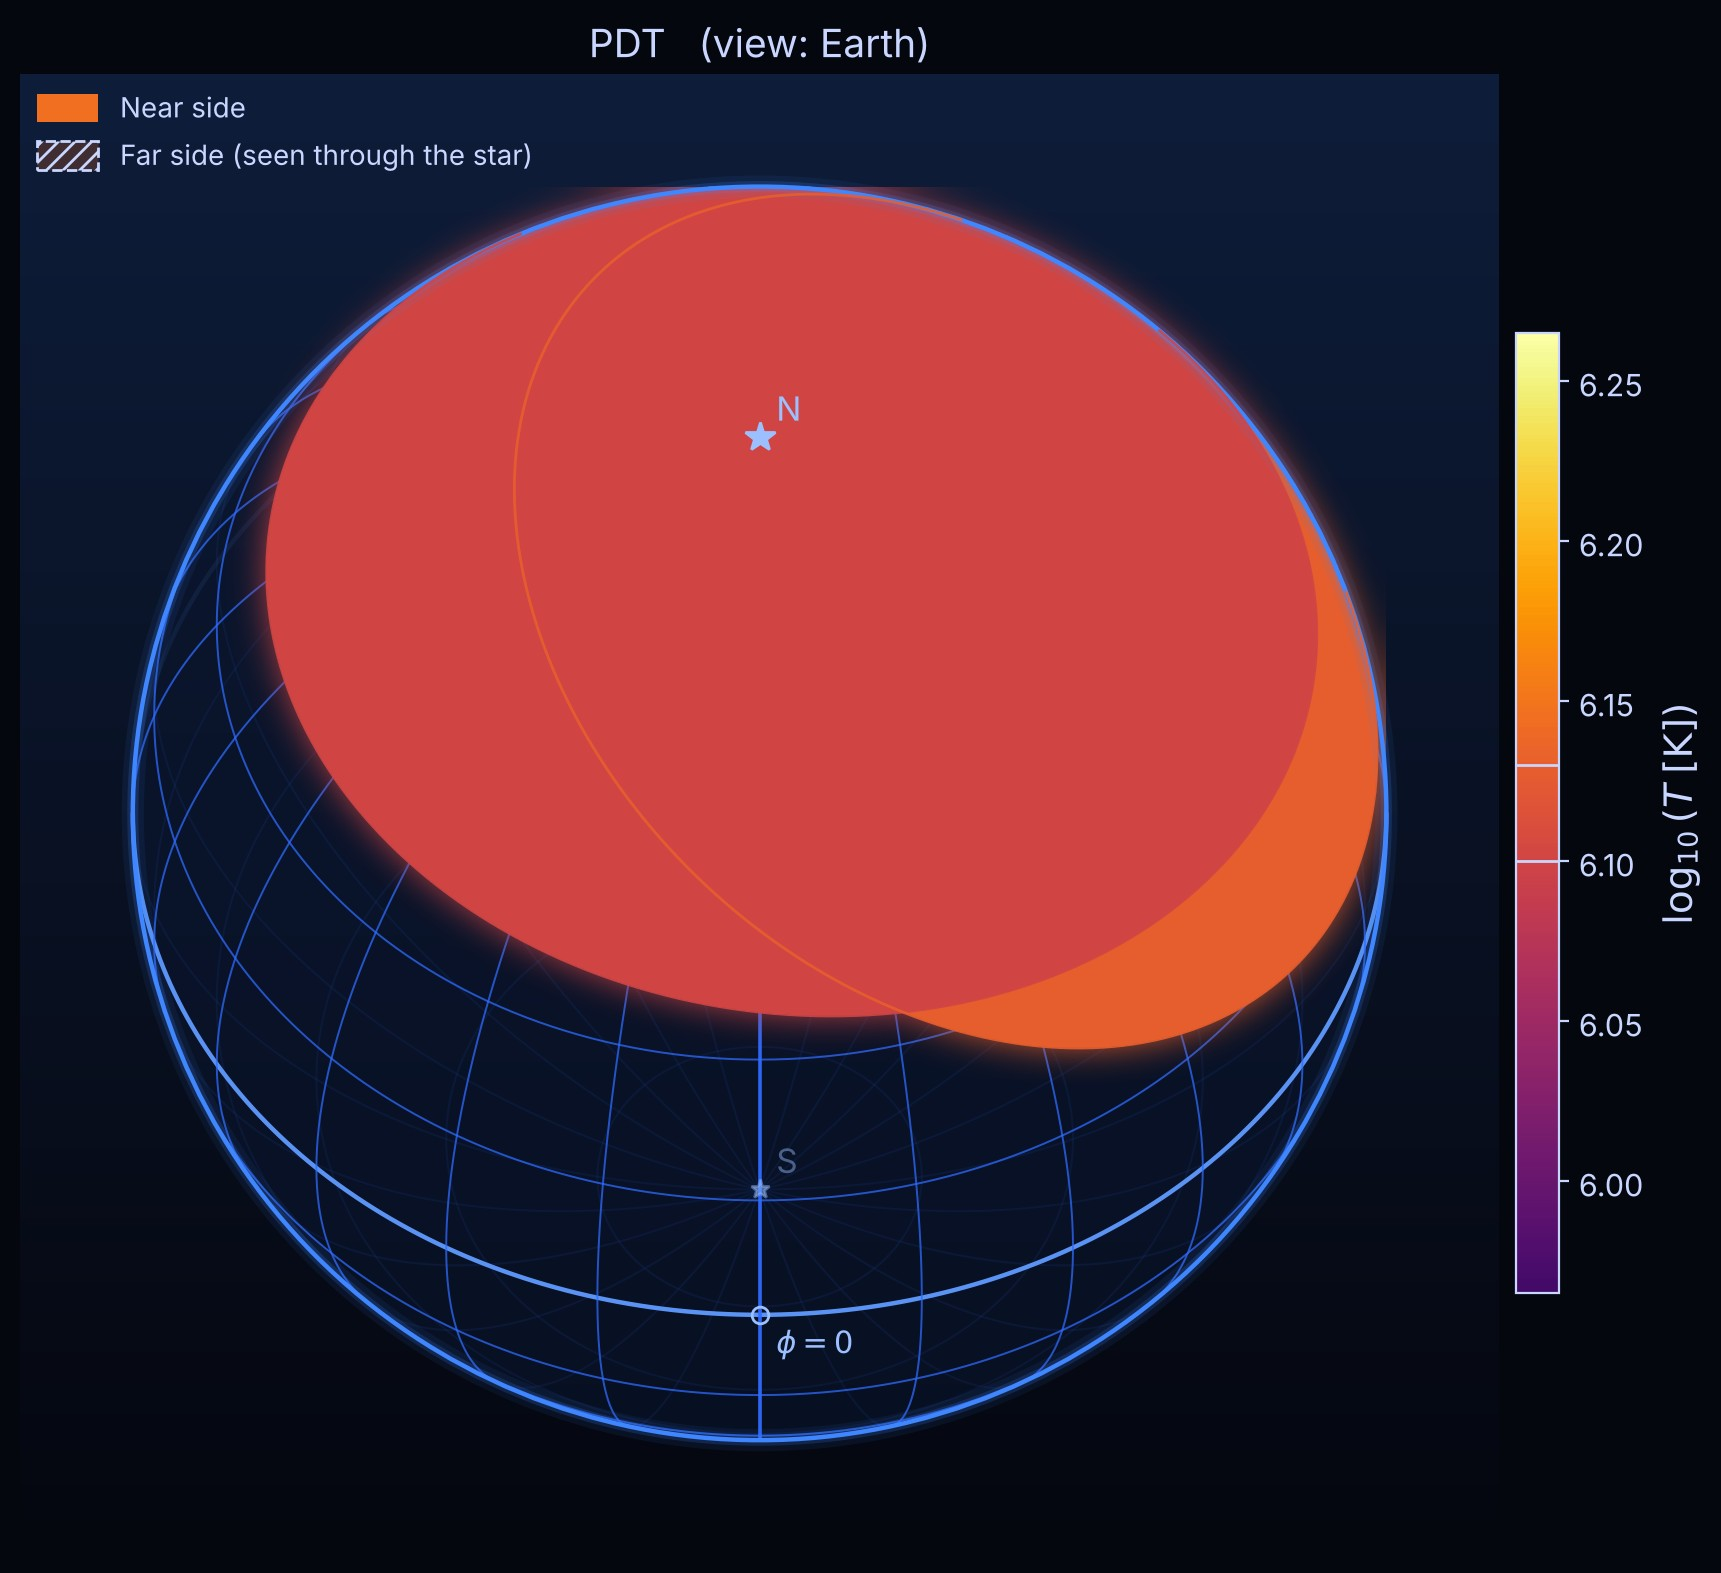

In [8]:
labels_1hsDT = ['mass', 'radius', 'cos_inclination',
                'p__phase_shift', 'p__super_colatitude', 'p__super_radius', 'p__super_temperature',
                'p__cede_colatitude', 'p__cede_radius', 'p__cede_azimuth', 'p__cede_temperature',
                'beta', 'column_density']

values_1hsDT = [1.2, 12, 0.8, 0.3, 0.1, 1.0, 6.1, 0.5, 0.9, -0.4, 6.13, 9.3, 0.8]

P_dictionary_1hsDT = dict(zip(labels_1hsDT, values_1hsDT))
plot_projection_filled(P_dictionary_1hsDT, "PDT", "I", show_outlines=True);

Here the ceding region (log T = 6.13) is only visible as the sliver the superseding region (log T = 6.10) doesn't cover. Both temperatures are marked on the colour bar.

If the model is declared concentric (`"CDT"`), the ceding component is centred on the superseding one and its colatitude and azimuth parameters are ignored. A concentric ceding region is only visible if it is larger than the superseding one:

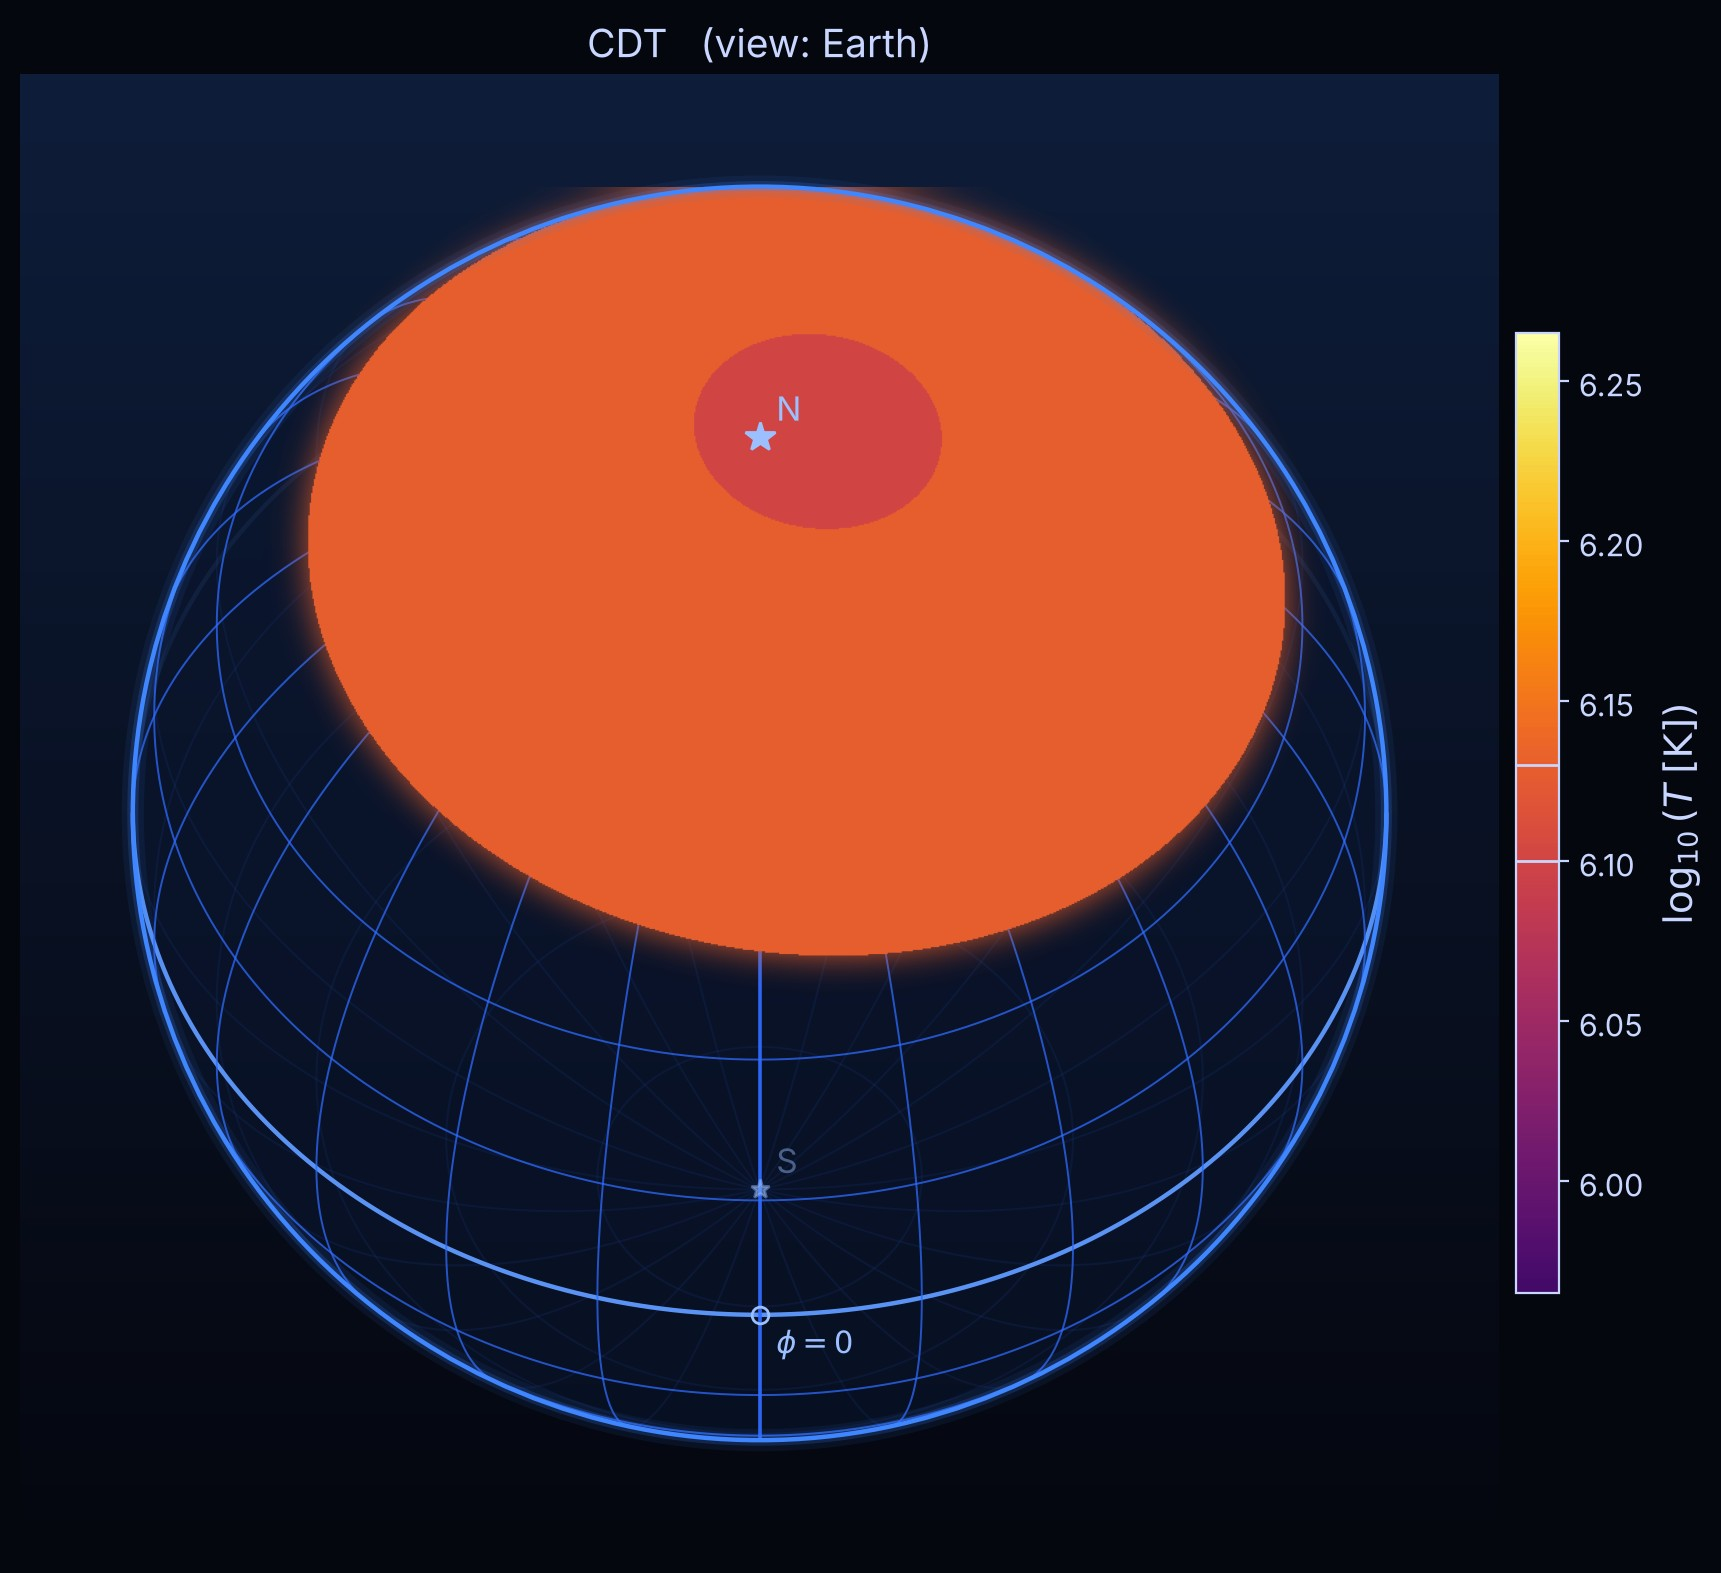

In [9]:
P_dictionary_1hsDT['p__super_radius'] = 0.2
plot_projection_filled(P_dictionary_1hsDT, "CDT", "I");

For double-temperature models you can centre the projection on either component, `"PS"` (superseding) or `"PC"` (ceding):

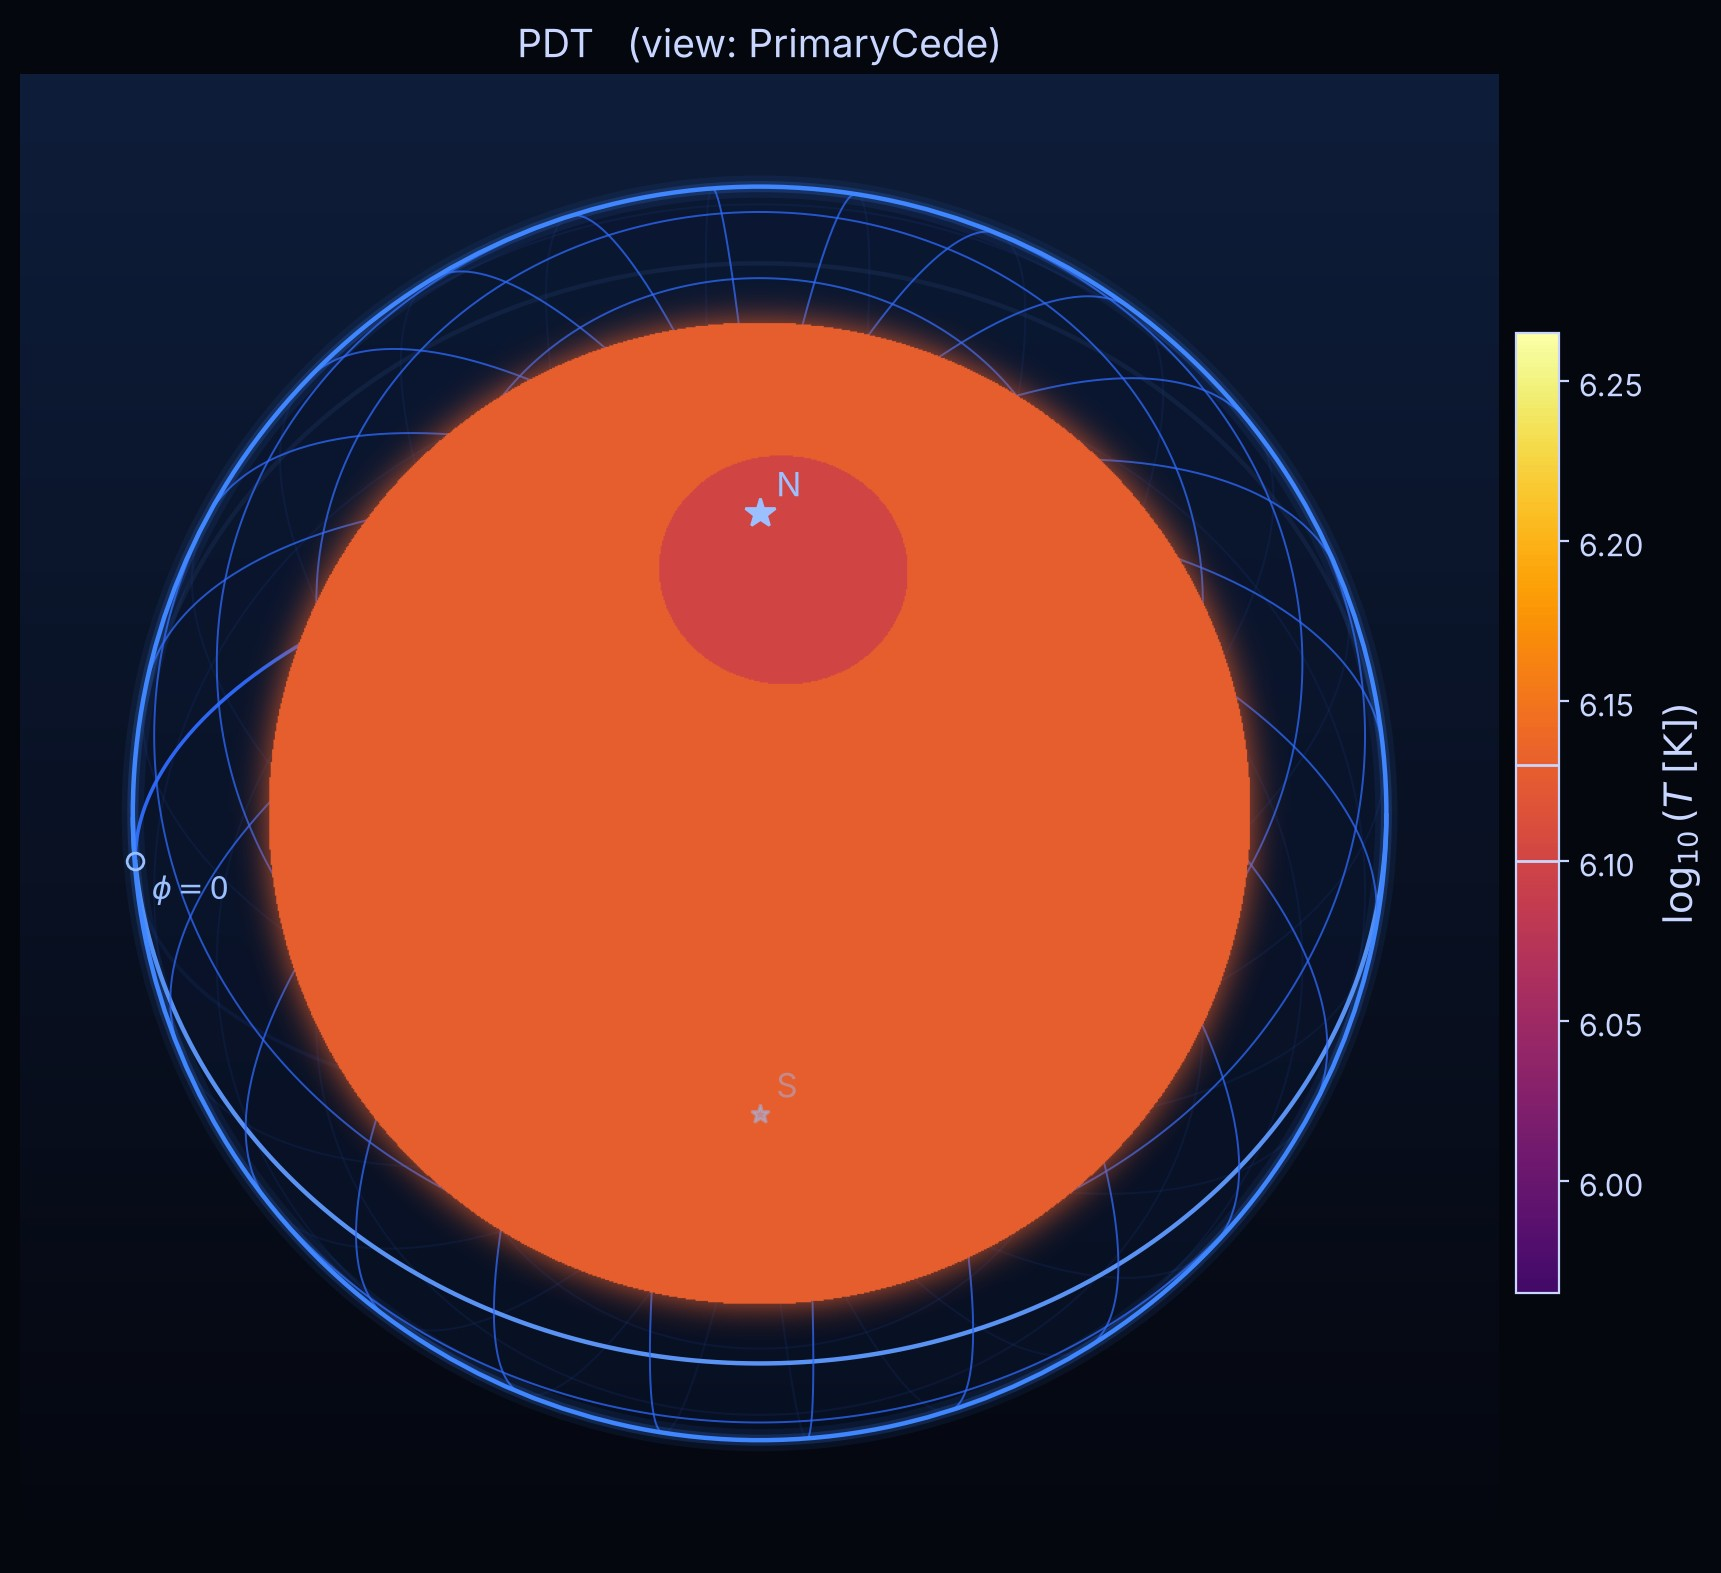

In [10]:
plot_projection_filled(P_dictionary_1hsDT, "PDT", "PC");

### 1.3) Single temperature with an omission region (PST, CST)
The omission region has zero temperature, so only the part of the emitting region outside it is coloured. With `show_outlines=True` the omission region is shown as a dashed line.

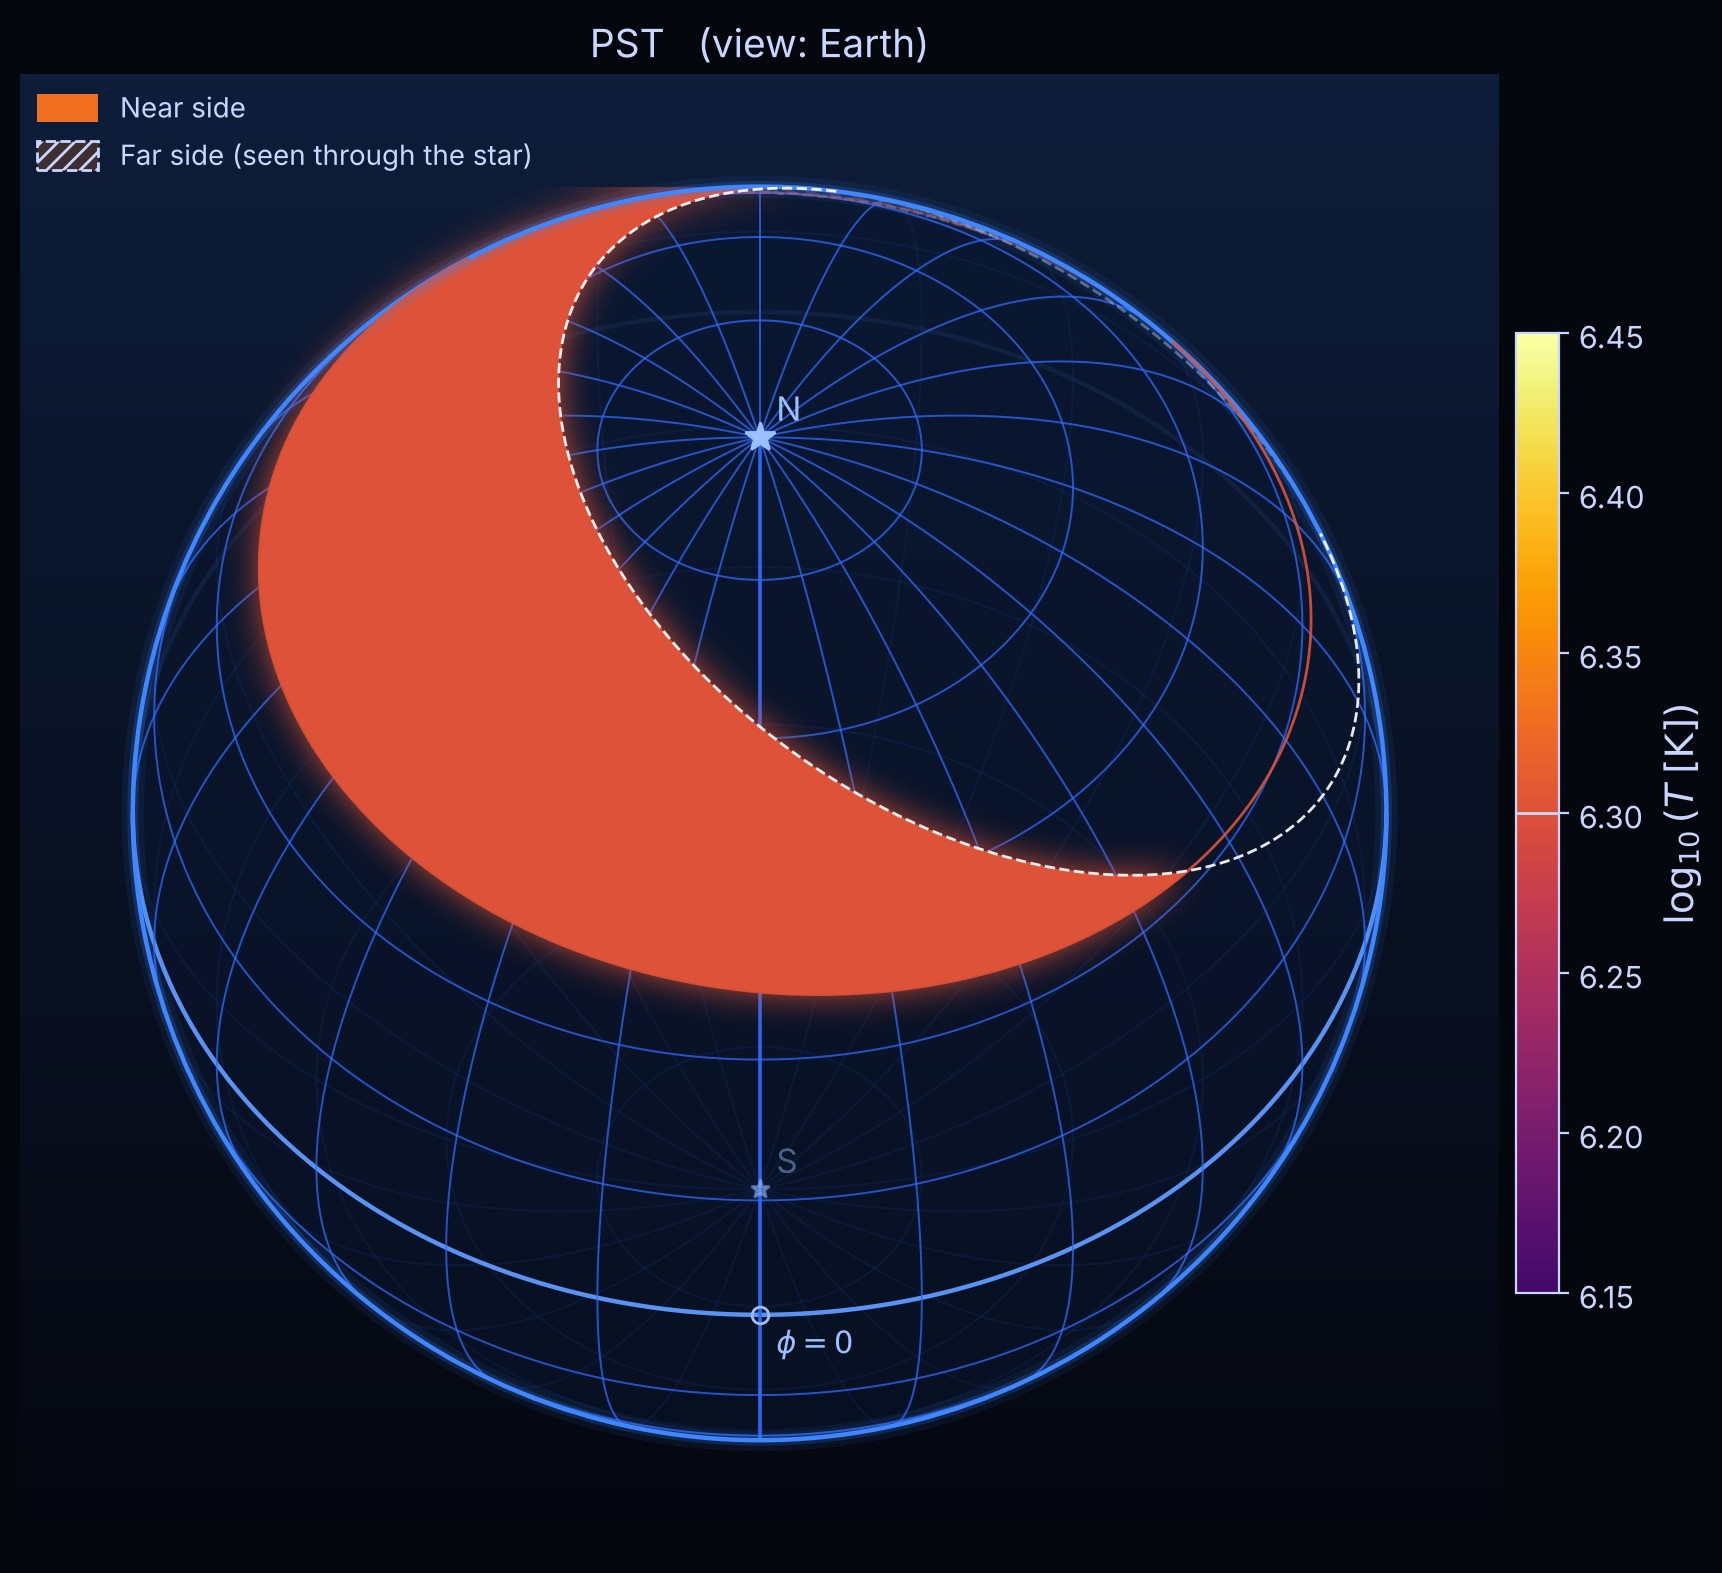

In [11]:
labels_1hsPST = ['mass', 'radius', 'cos_inclination',
                 'p__phase_shift', 'p__super_colatitude', 'p__super_radius', 'p__super_temperature',
                 'p__omit_colatitude', 'p__omit_radius', 'p__omit_azimuth',
                 'beta', 'column_density']

values_1hsPST = [1.2, 14, 0.8, 0.3, 0.1, 1.0, 6.3, 0.5, 0.8, -0.4, 9.3, 0.8]

P_dictionary_1hsPST = dict(zip(labels_1hsPST, values_1hsPST))
plot_projection_filled(P_dictionary_1hsPST, "PST", "I", show_outlines=True);

Declaring the same parameters as concentric (`"CST"`) turns the crescent into a ring:

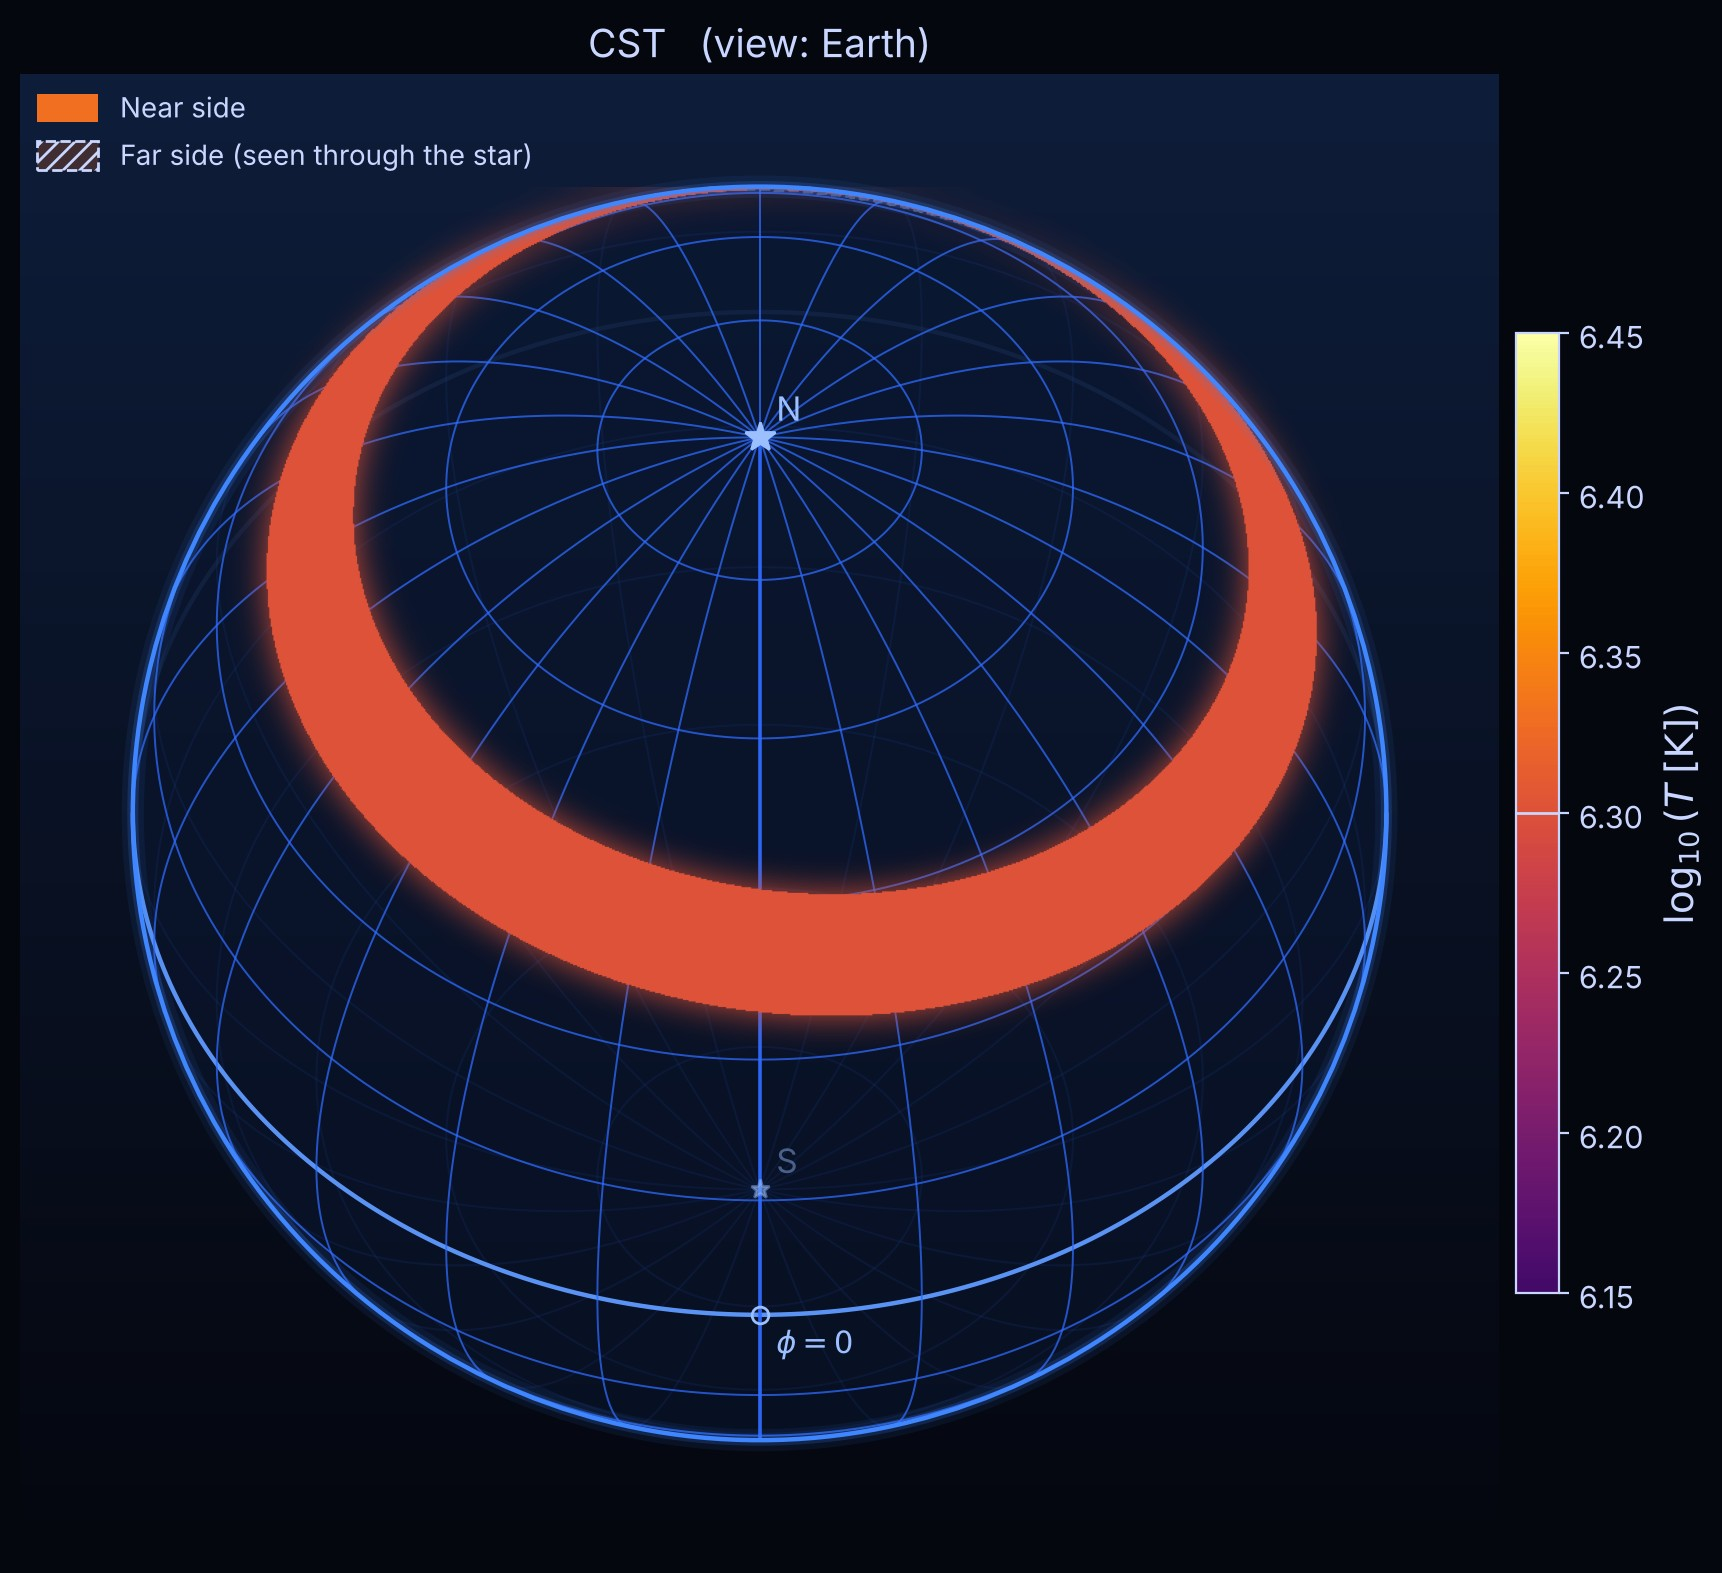

In [12]:
plot_projection_filled(P_dictionary_1hsPST, "CST", "I");

The allowed points of view depend on the model. If you give one that isn't allowed, the error message lists the options:

In [13]:
try:
    plot_projection_filled(P_dictionary_1hsPST, "PST", "PC")
except ValueError as err:
    print(err)

Point of view 'PC' not allowed for this model. Possibilities are: ['I', 'PE', 'PO']


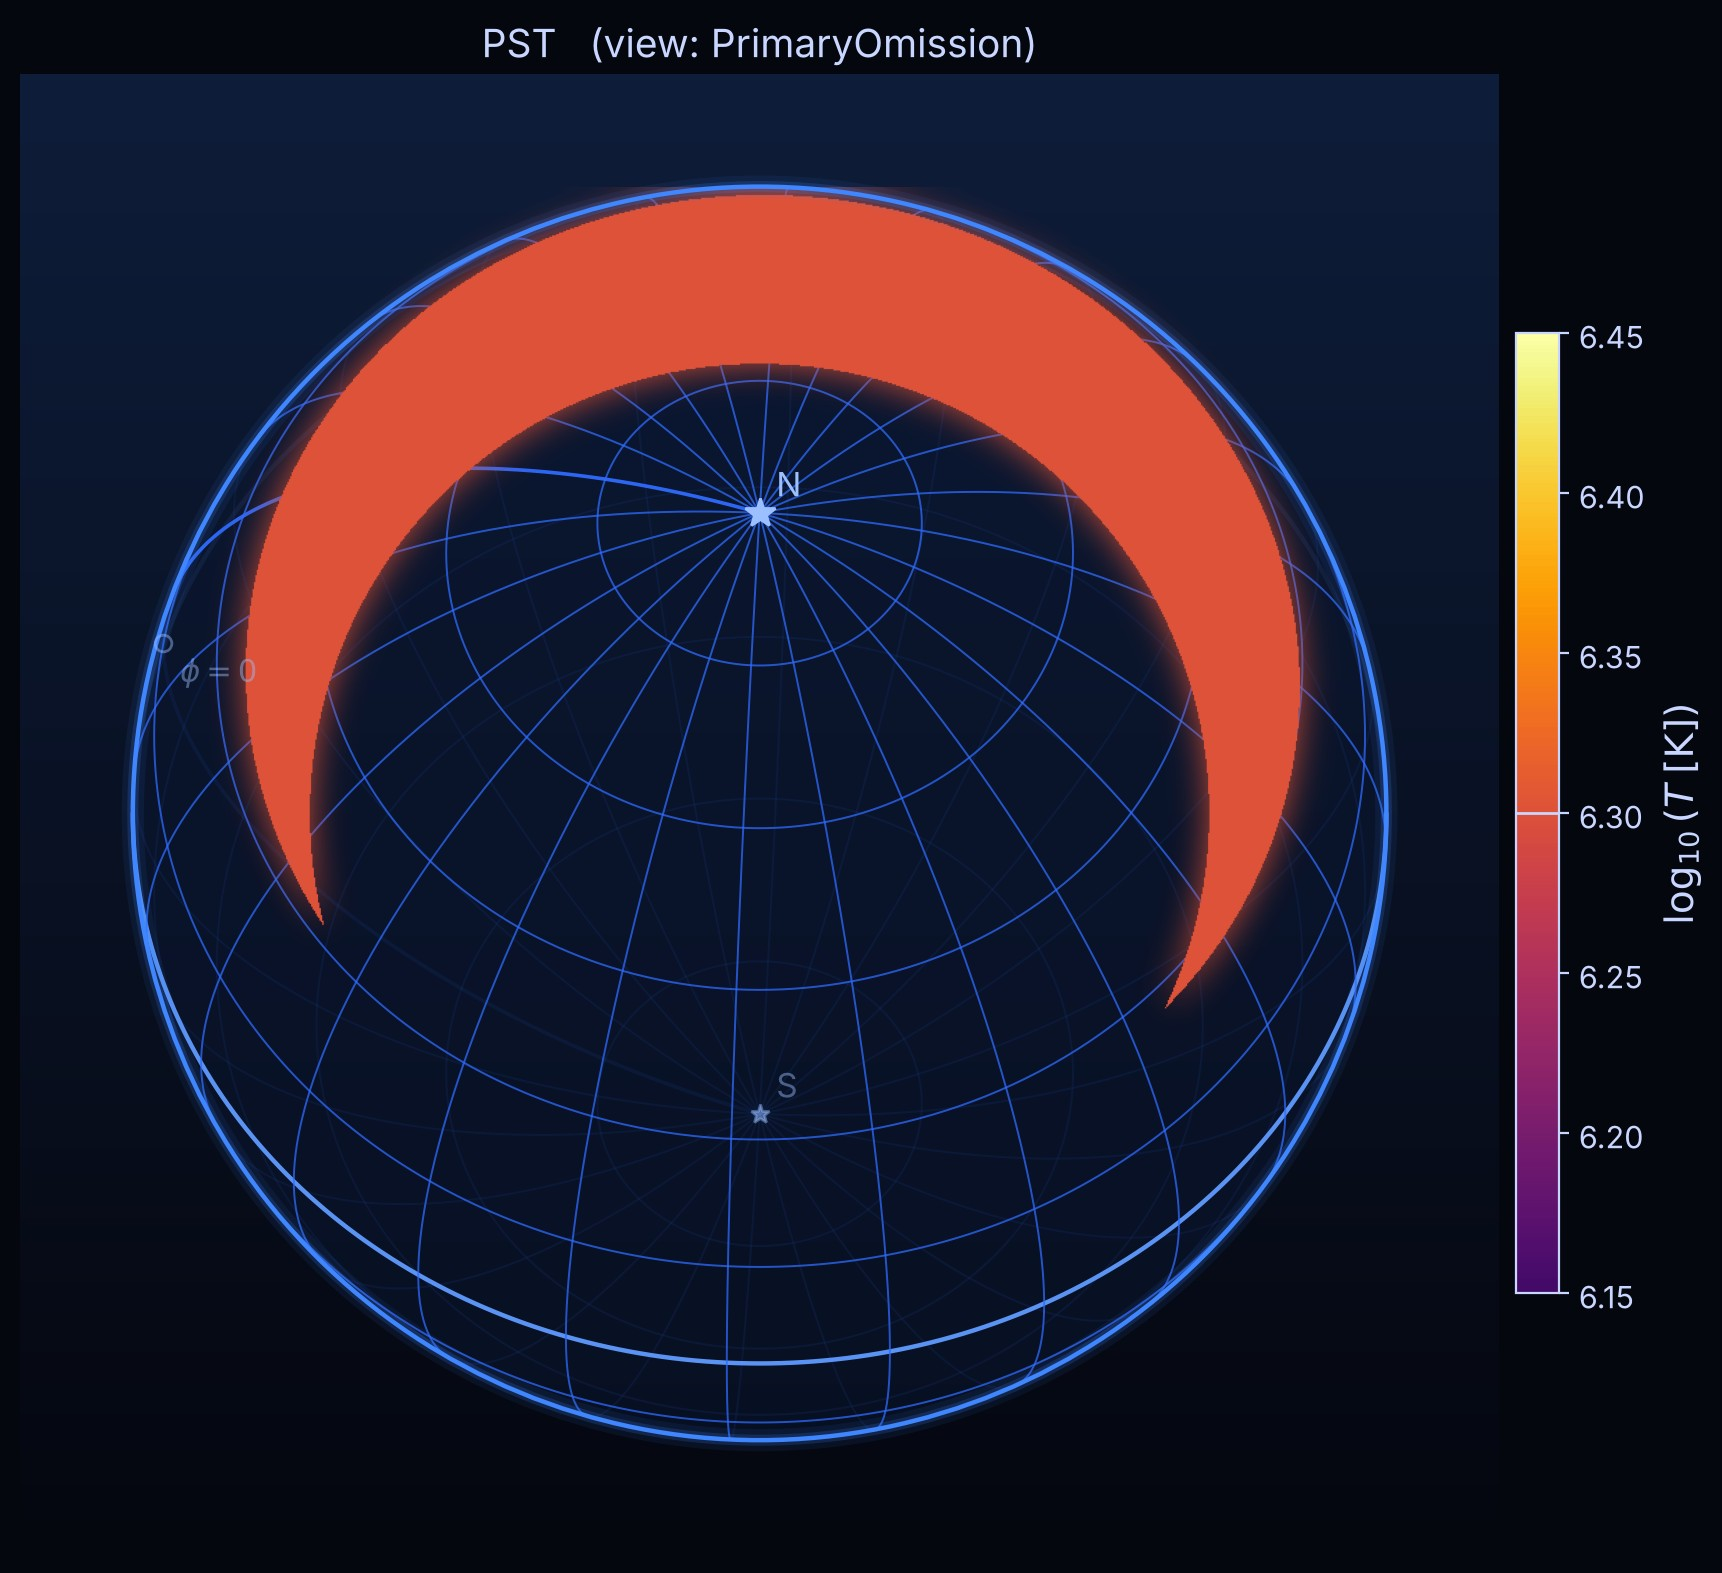

In [14]:
plot_projection_filled(P_dictionary_1hsPST, "PST", "PO");

## 2) Two hot regions
### 2.1) Different types of hot region (ST+PDT, ST+CST, PDT+PST)

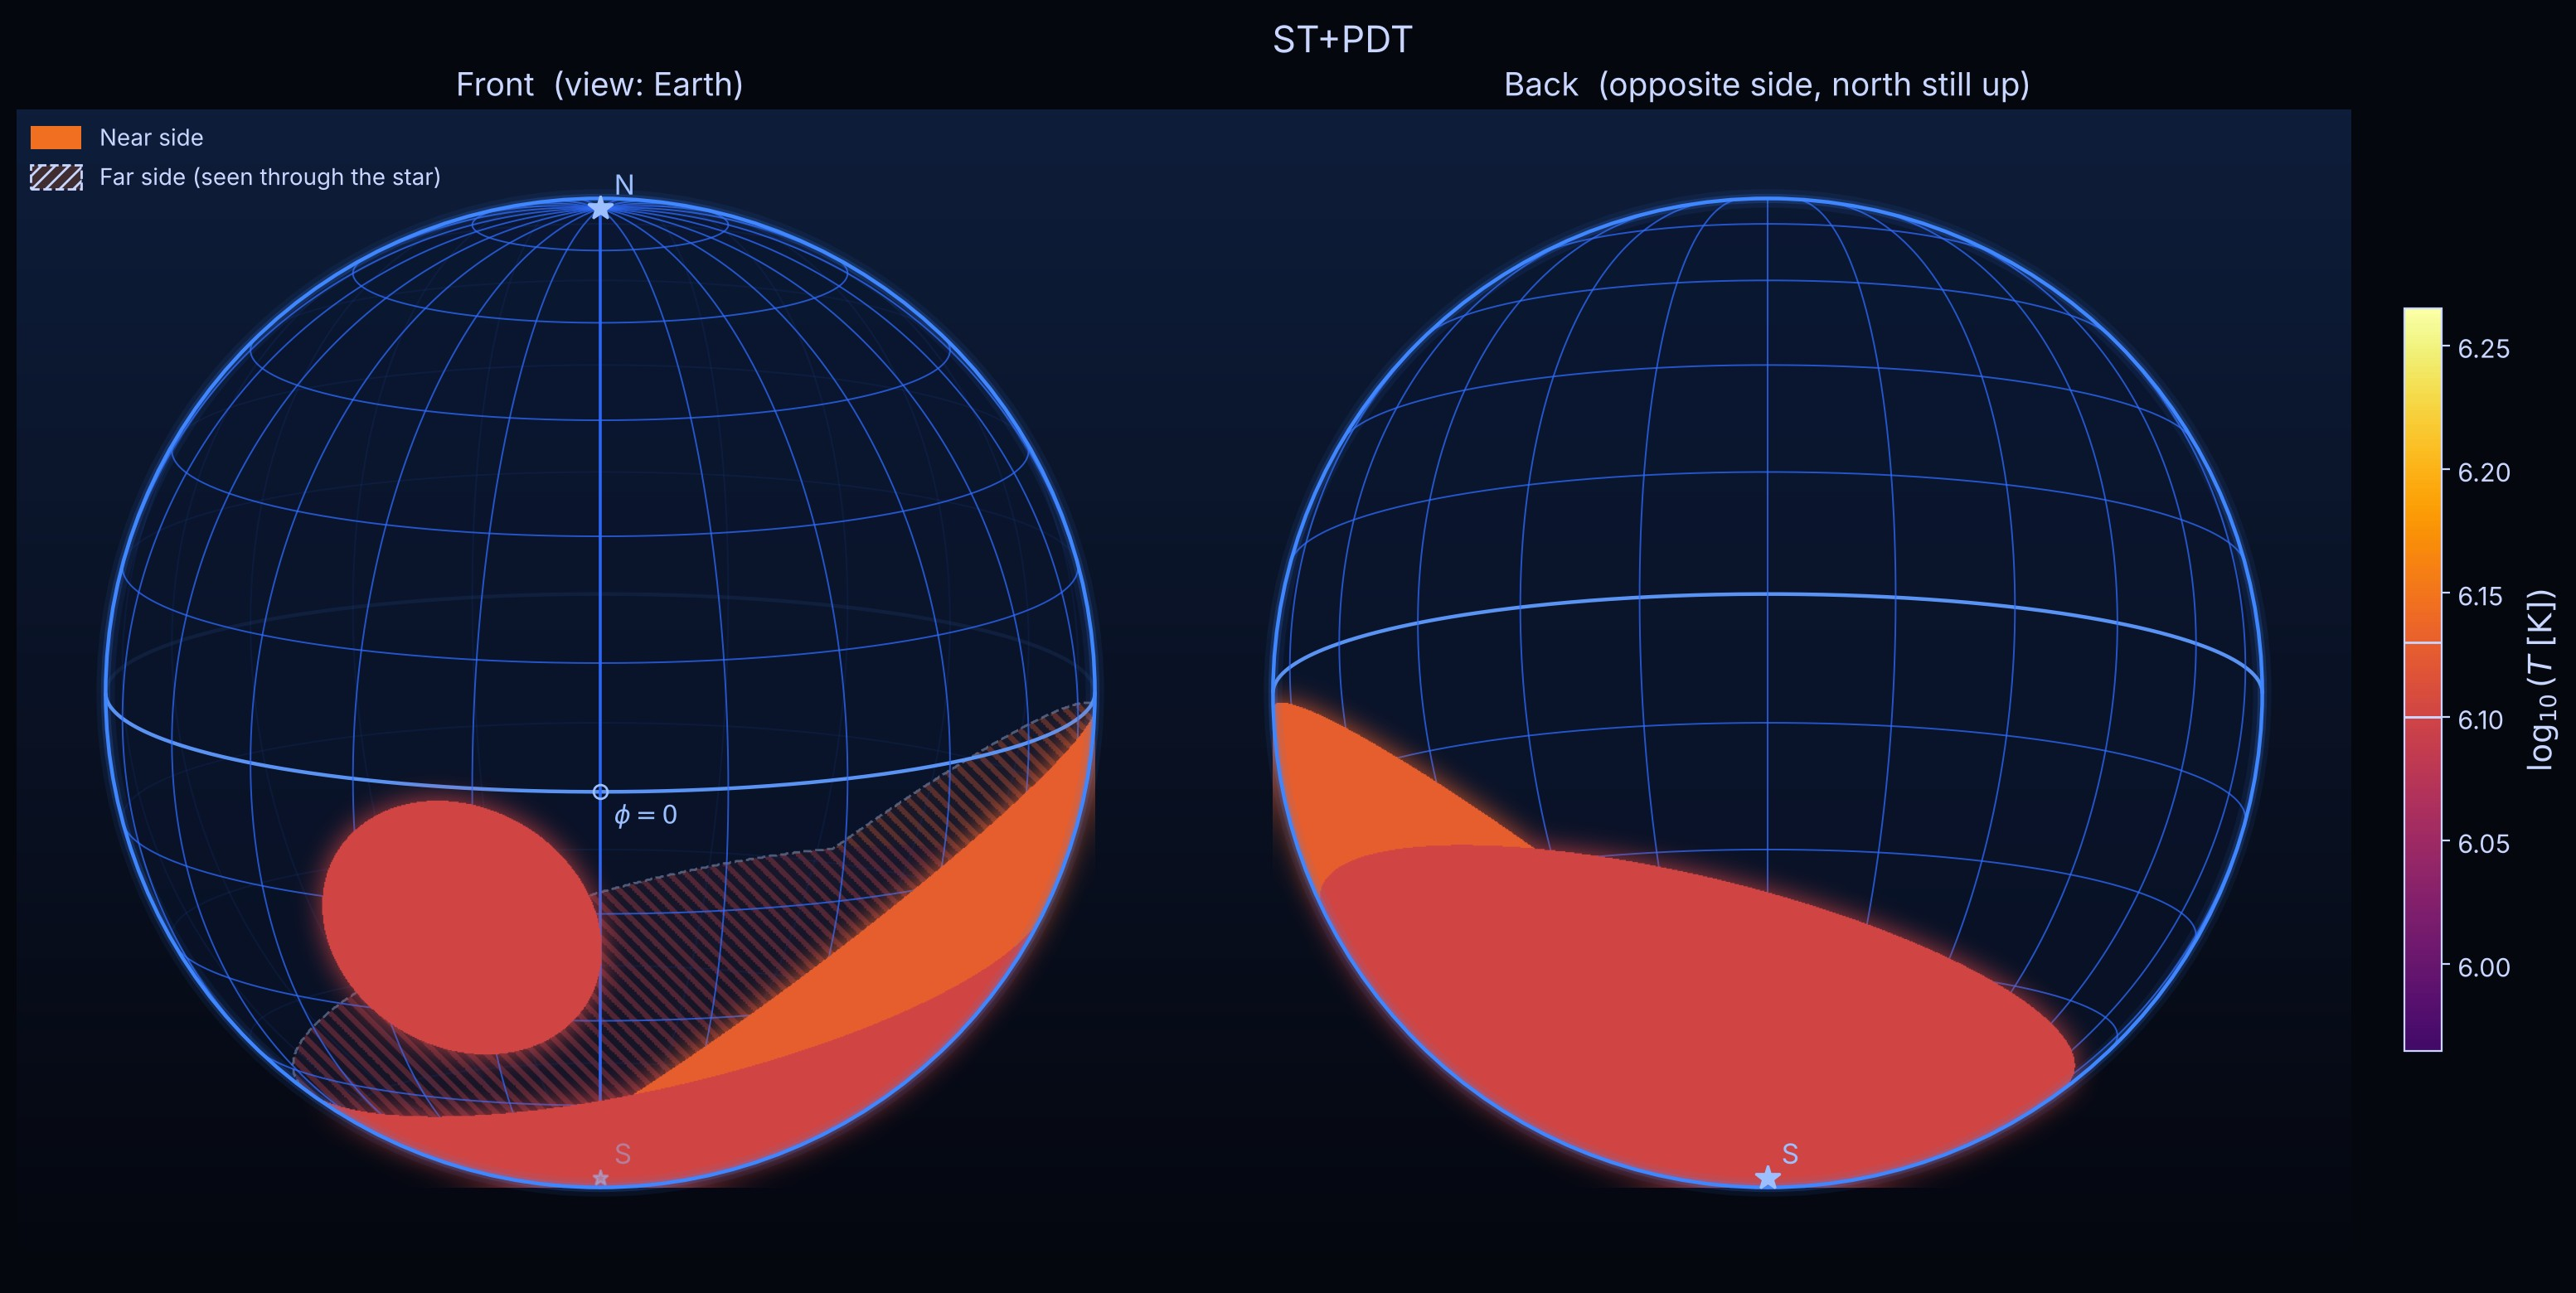

In [15]:
labels_2hsSTPDT = ['mass', 'radius', 'cos_inclination',
                   'p__phase_shift', 'p__super_colatitude', 'p__super_radius', 'p__super_temperature',
                   's__phase_shift', 's__super_colatitude', 's__super_radius', 's__super_temperature',
                   's__cede_colatitude', 's__cede_radius', 's__cede_azimuth', 's__cede_temperature',
                   'beta', 'column_density']

values_2hsSTPDT = [1.2, 12, 0.2, -0.05, 1.9, 0.3, 6.1, 0.3, 2.9, 0.9, 6.1, 2.5, 0.9, -0.4, 6.13, 9.3, 0.8]

P_dictionary_2hsSTPDT = dict(zip(labels_2hsSTPDT, values_2hsSTPDT))
plot_projection_filled(P_dictionary_2hsSTPDT, "ST+PDT", "I", back_view=True);

Centred on the secondary's superseding component, with the position antipodal to the primary marked (`antipodal=True`):

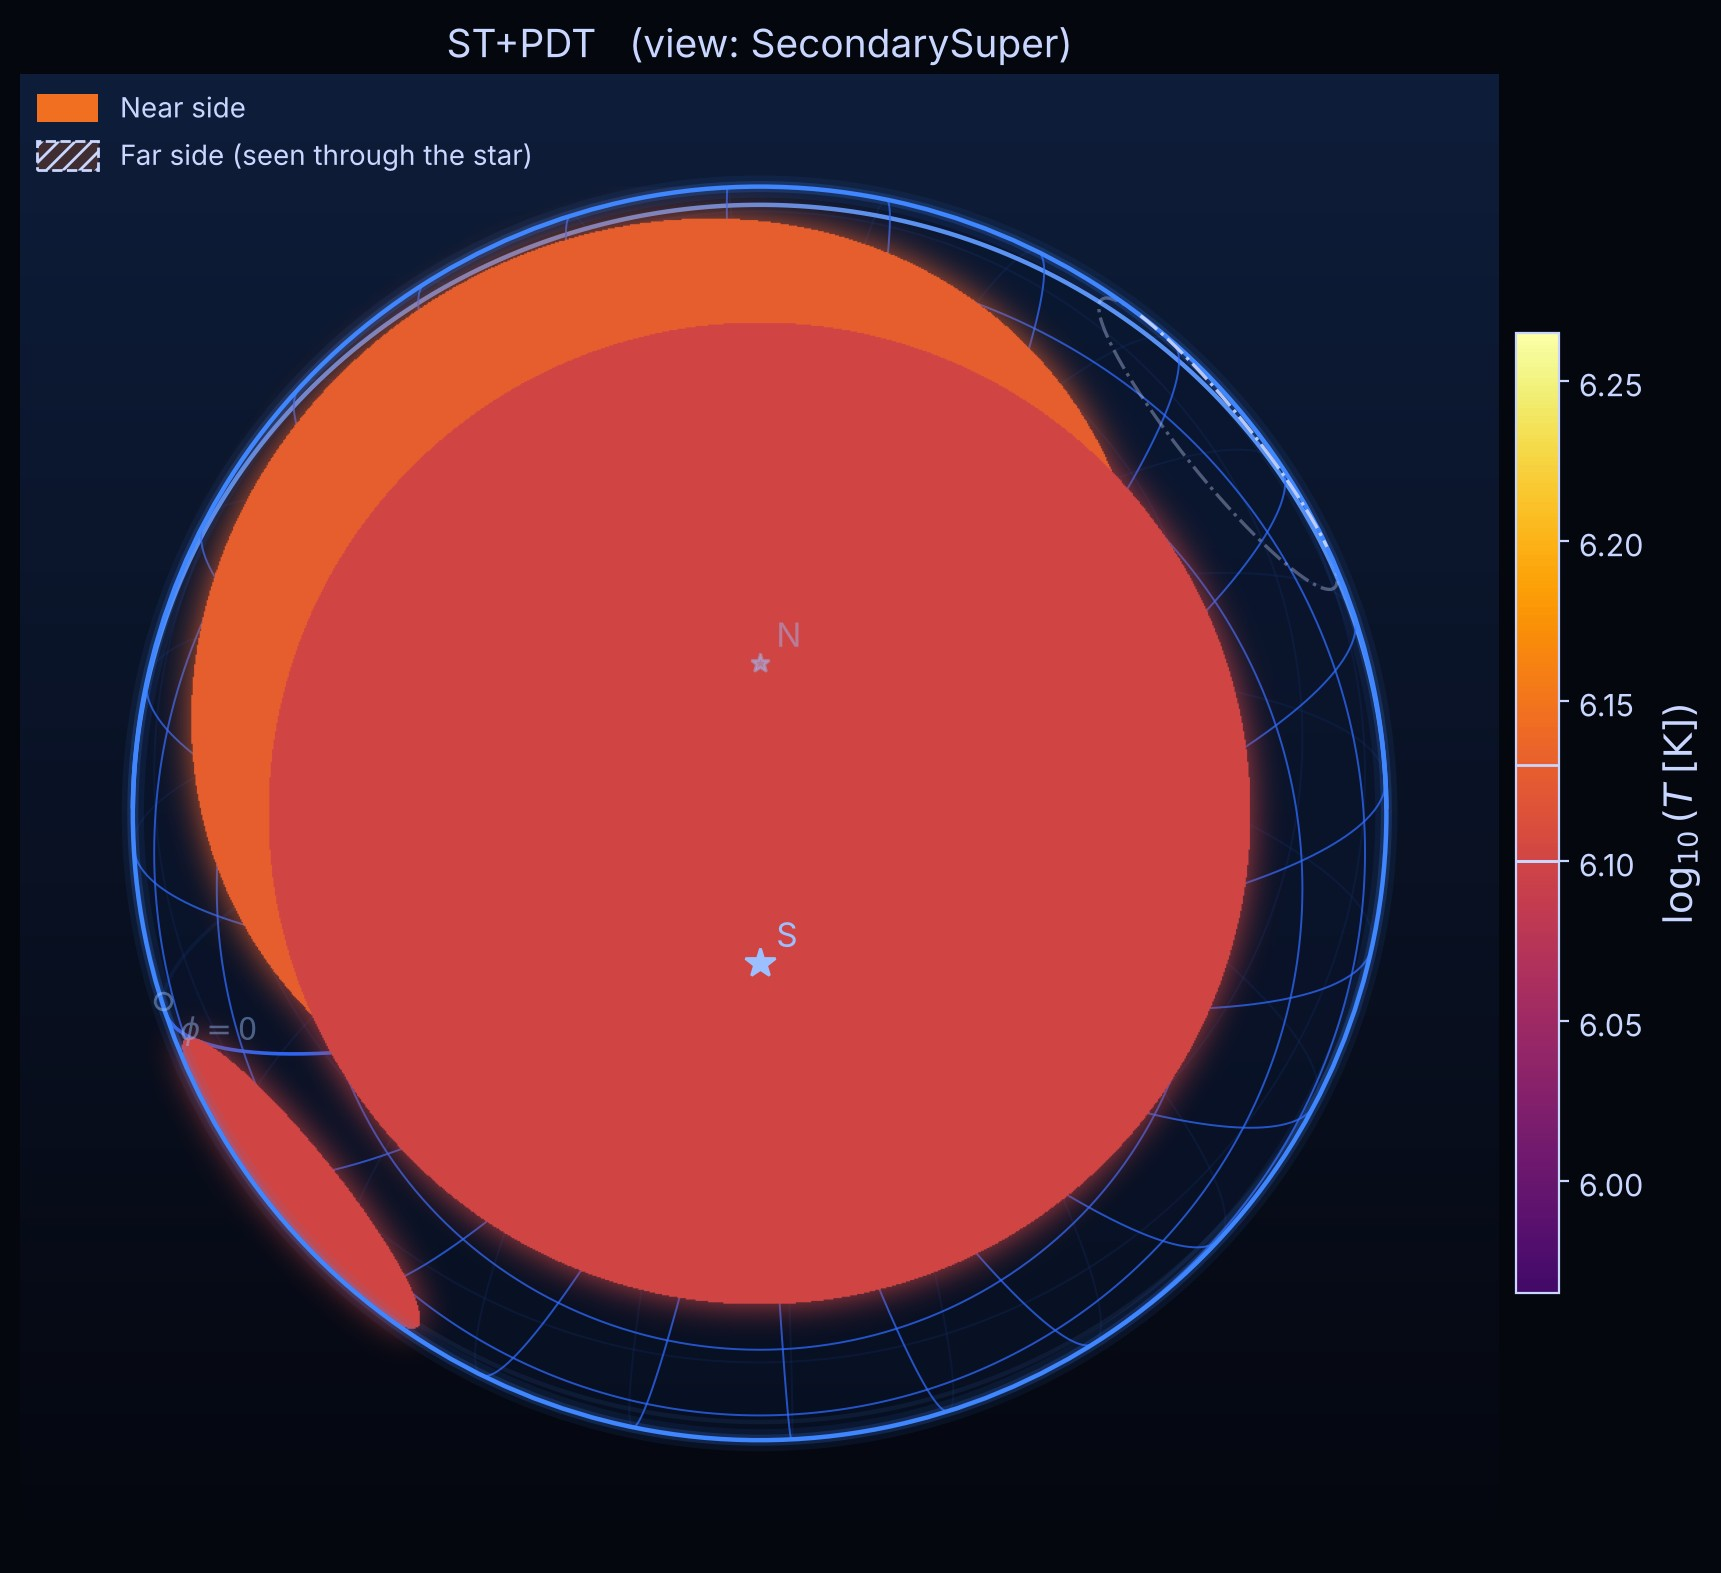

In [16]:
plot_projection_filled(P_dictionary_2hsSTPDT, "ST+PDT", "SS", antipodal=True);

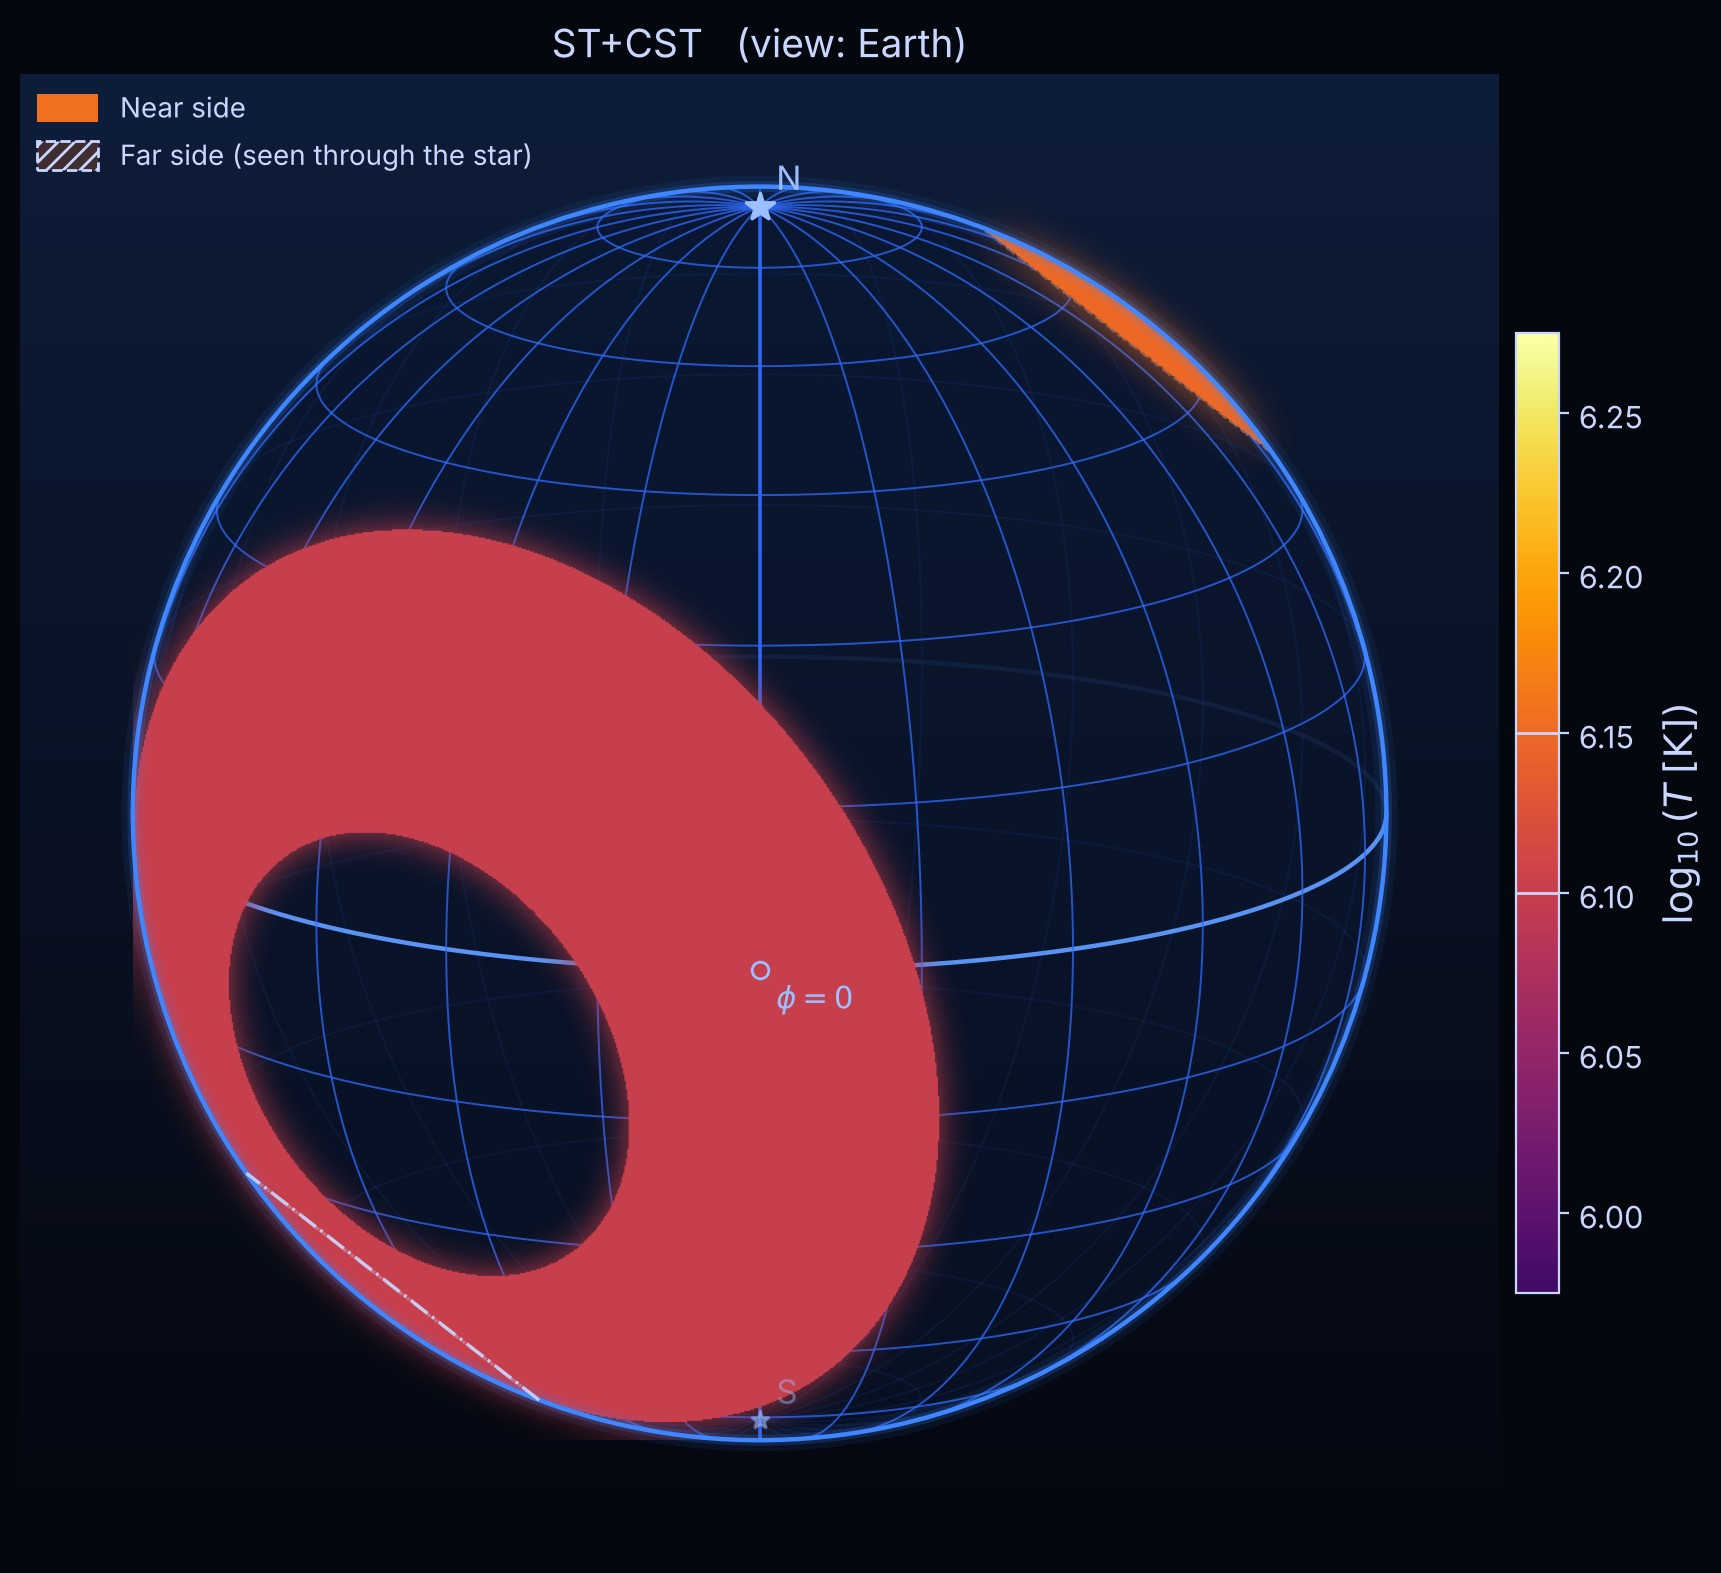

In [17]:
labels_2hsSTCST = ['mass', 'radius', 'cos_inclination',
                   'p__phase_shift', 'p__super_colatitude', 'p__super_radius', 'p__super_temperature',
                   's__phase_shift', 's__super_colatitude', 's__super_radius', 's__super_temperature',
                   's__omit_radius',
                   'beta', 'column_density']

values_2hsSTCST = [1.4, 15, 0.25, 0.3, 0.7, 0.3, 6.15, -0.1, 1.8, 0.9, 6.1, 0.4, 9.3, 0.8]

P_dictionary_2hsSTCST = dict(zip(labels_2hsSTCST, values_2hsSTCST))
plot_projection_filled(P_dictionary_2hsSTCST, "ST+CST", "I", antipodal=True);

The secondary is a ring (the CST shape). The dash-dotted circle shows that the antipode of the primary would overlap the ring.

A PDT+PST model, with three different temperatures. Here the colour scale is fixed with `Tmin` and `Tmax`, as you would when comparing several figures (e.g. different posterior samples):

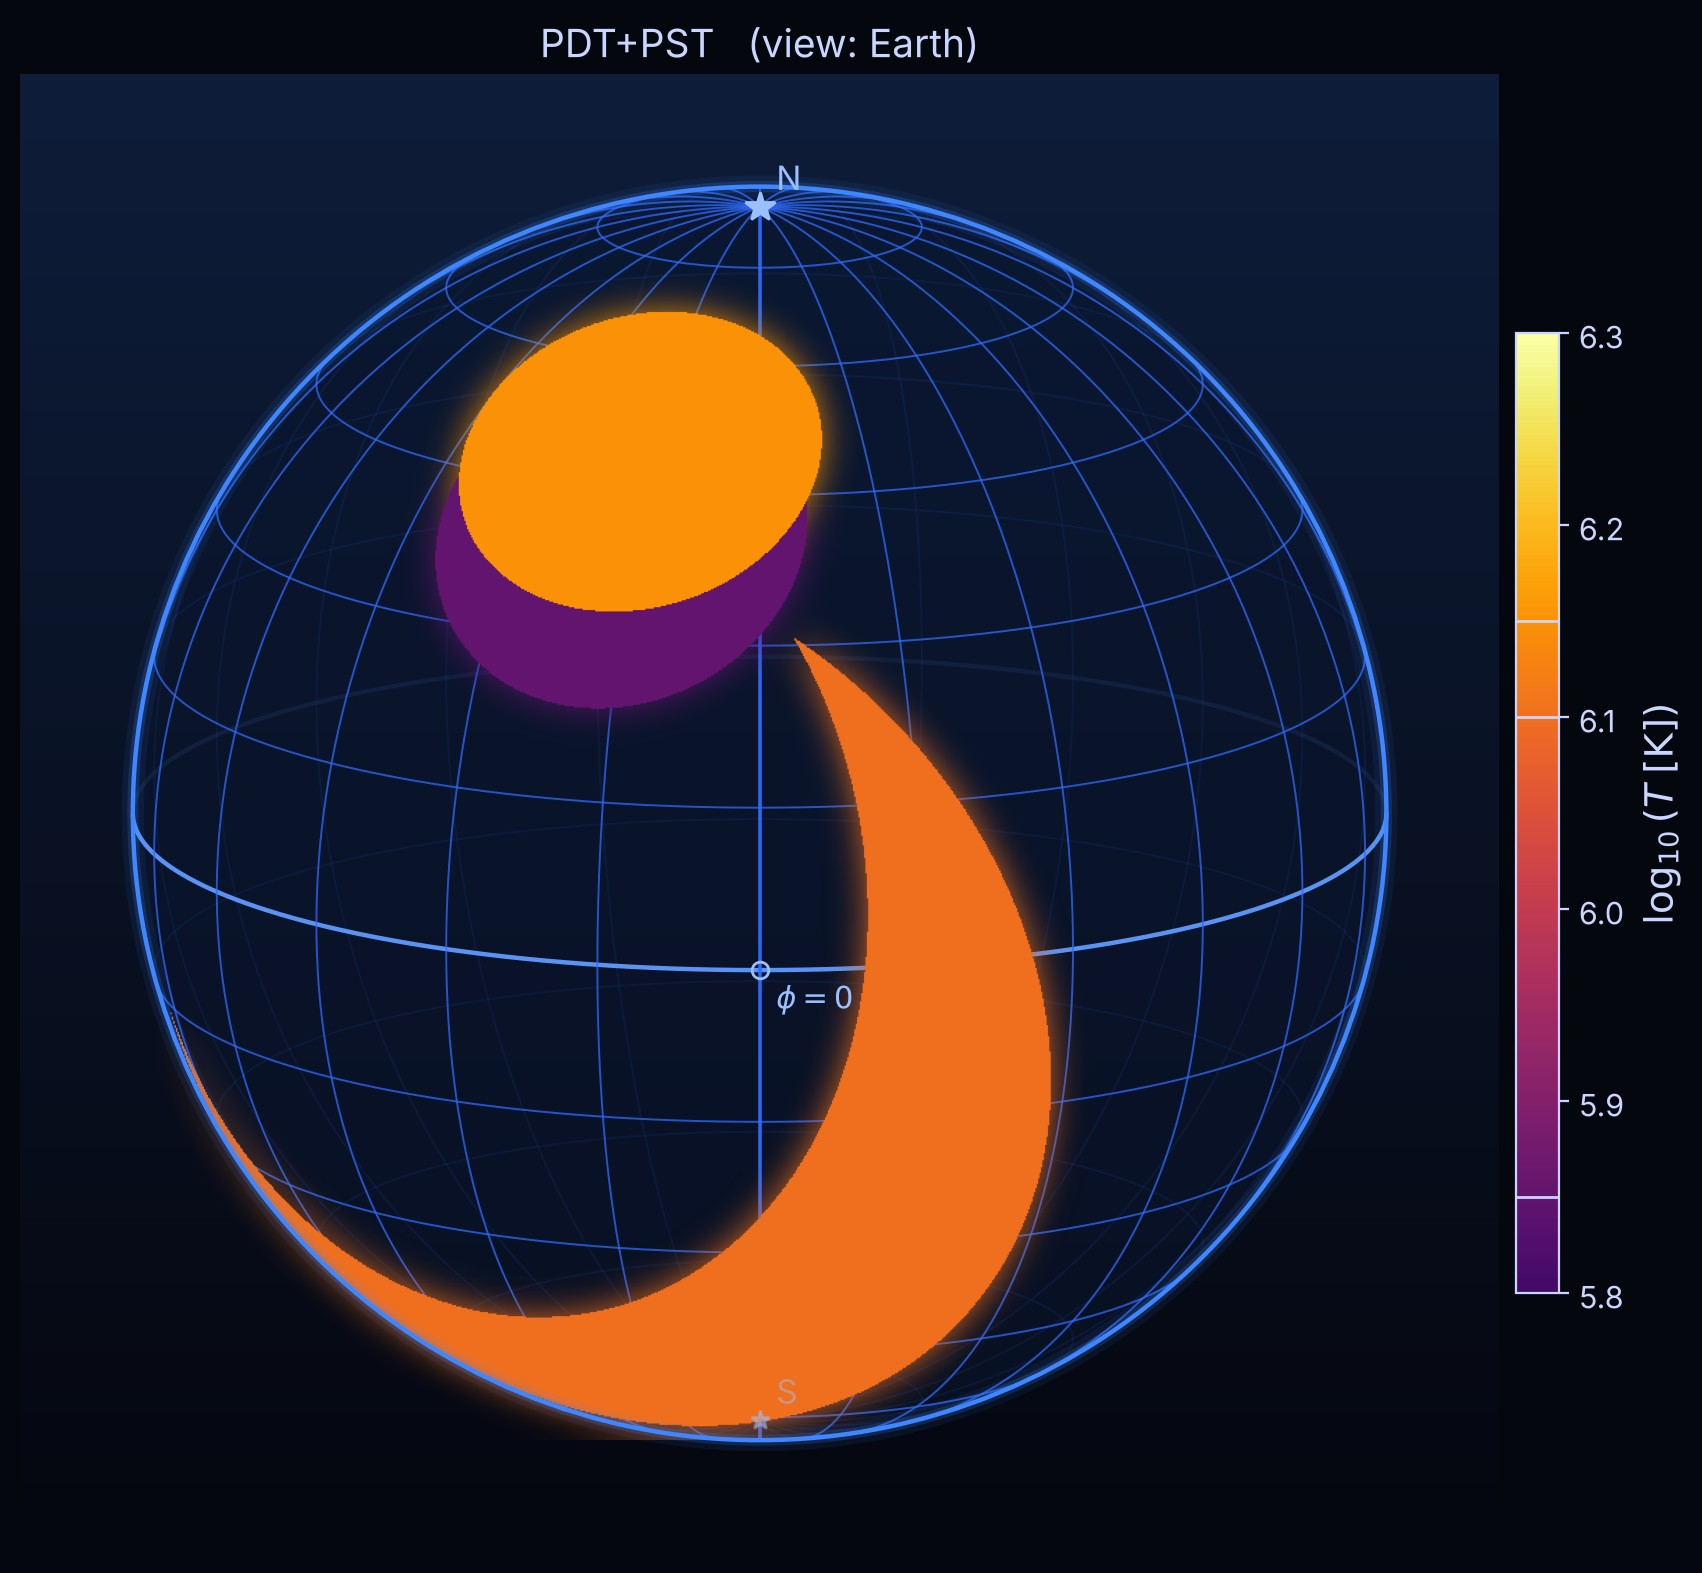

In [18]:
labels_2hsPDTPST = ['mass', 'radius', 'cos_inclination',
                    'p__phase_shift', 'p__super_colatitude', 'p__super_radius', 'p__super_temperature',
                    'p__cede_colatitude', 'p__cede_radius', 'p__cede_azimuth', 'p__cede_temperature',
                    's__phase_shift', 's__super_colatitude', 's__super_radius', 's__super_temperature',
                    's__omit_colatitude', 's__omit_radius', 's__omit_azimuth',
                    'beta', 'column_density']

values_2hsPDTPST = [1.4, 15, 0.25, 0.95, 0.7, 0.3, 6.15, 0.85, 0.31, 0.001, 5.85,
                    -0.1, 1.8, 0.9, 6.1, 1.5, 0.8, -0.2, 9.3, 0.8]

P_dictionary_2hsPDTPST = dict(zip(labels_2hsPDTPST, values_2hsPDTPST))
plot_projection_filled(P_dictionary_2hsPDTPST, "PDT+PST", "I", Tmin=5.8, Tmax=6.3);

### 2.2) Same type of hot region: symmetric (`-S`)
The secondary is antipodal to the primary and has the same angular radii and temperatures, so only `p__` parameters are needed. Seen from the north pole, the secondary crescent shows through from the far side:

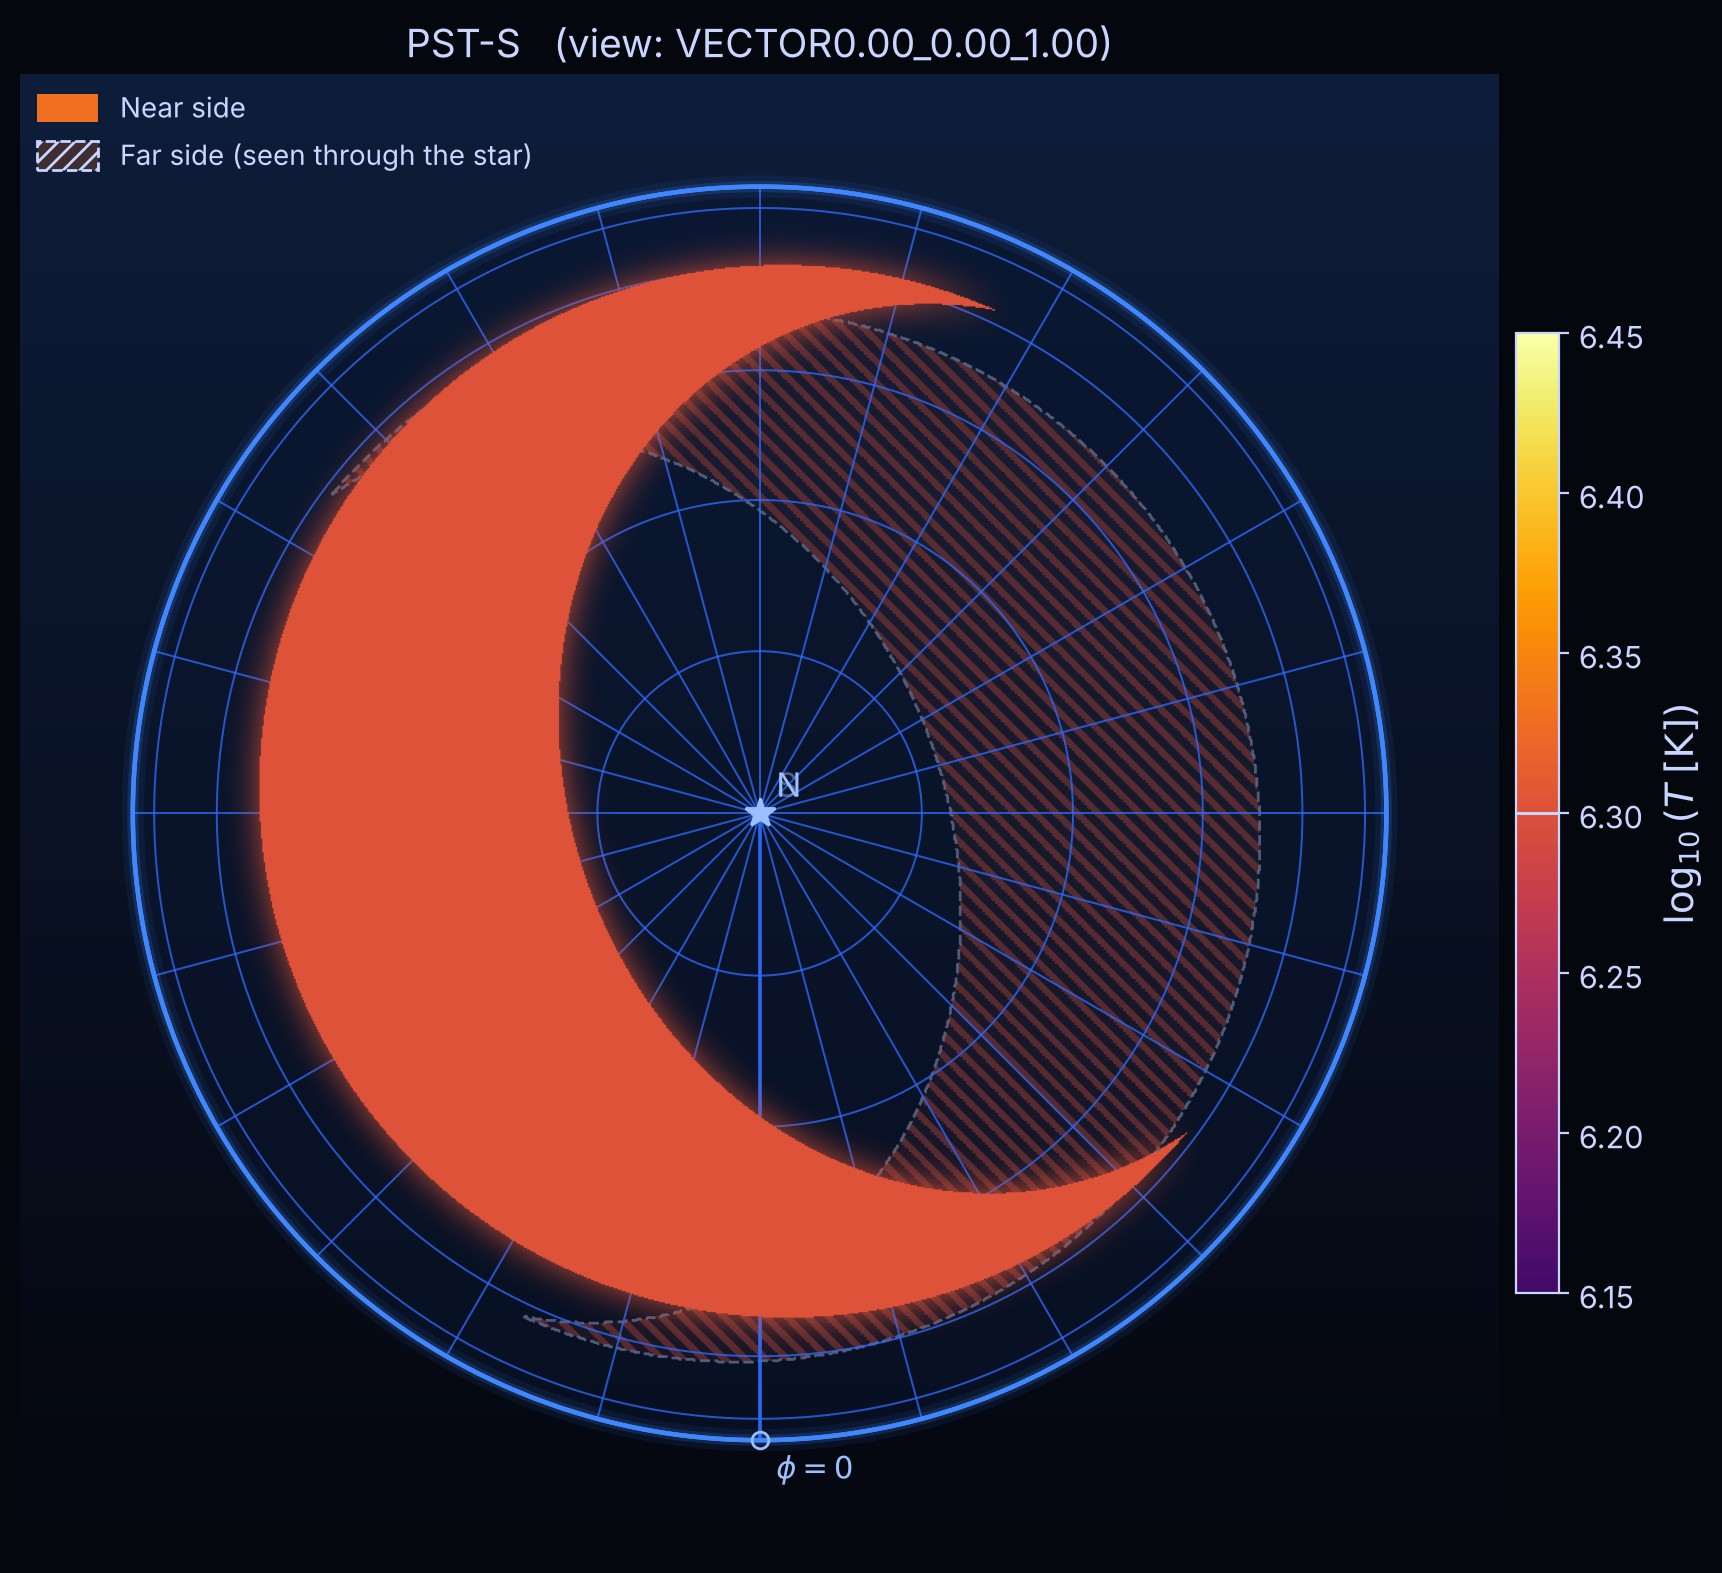

In [19]:
plot_projection_filled(P_dictionary_1hsPST, "PST-S", [0, 0, 1]);

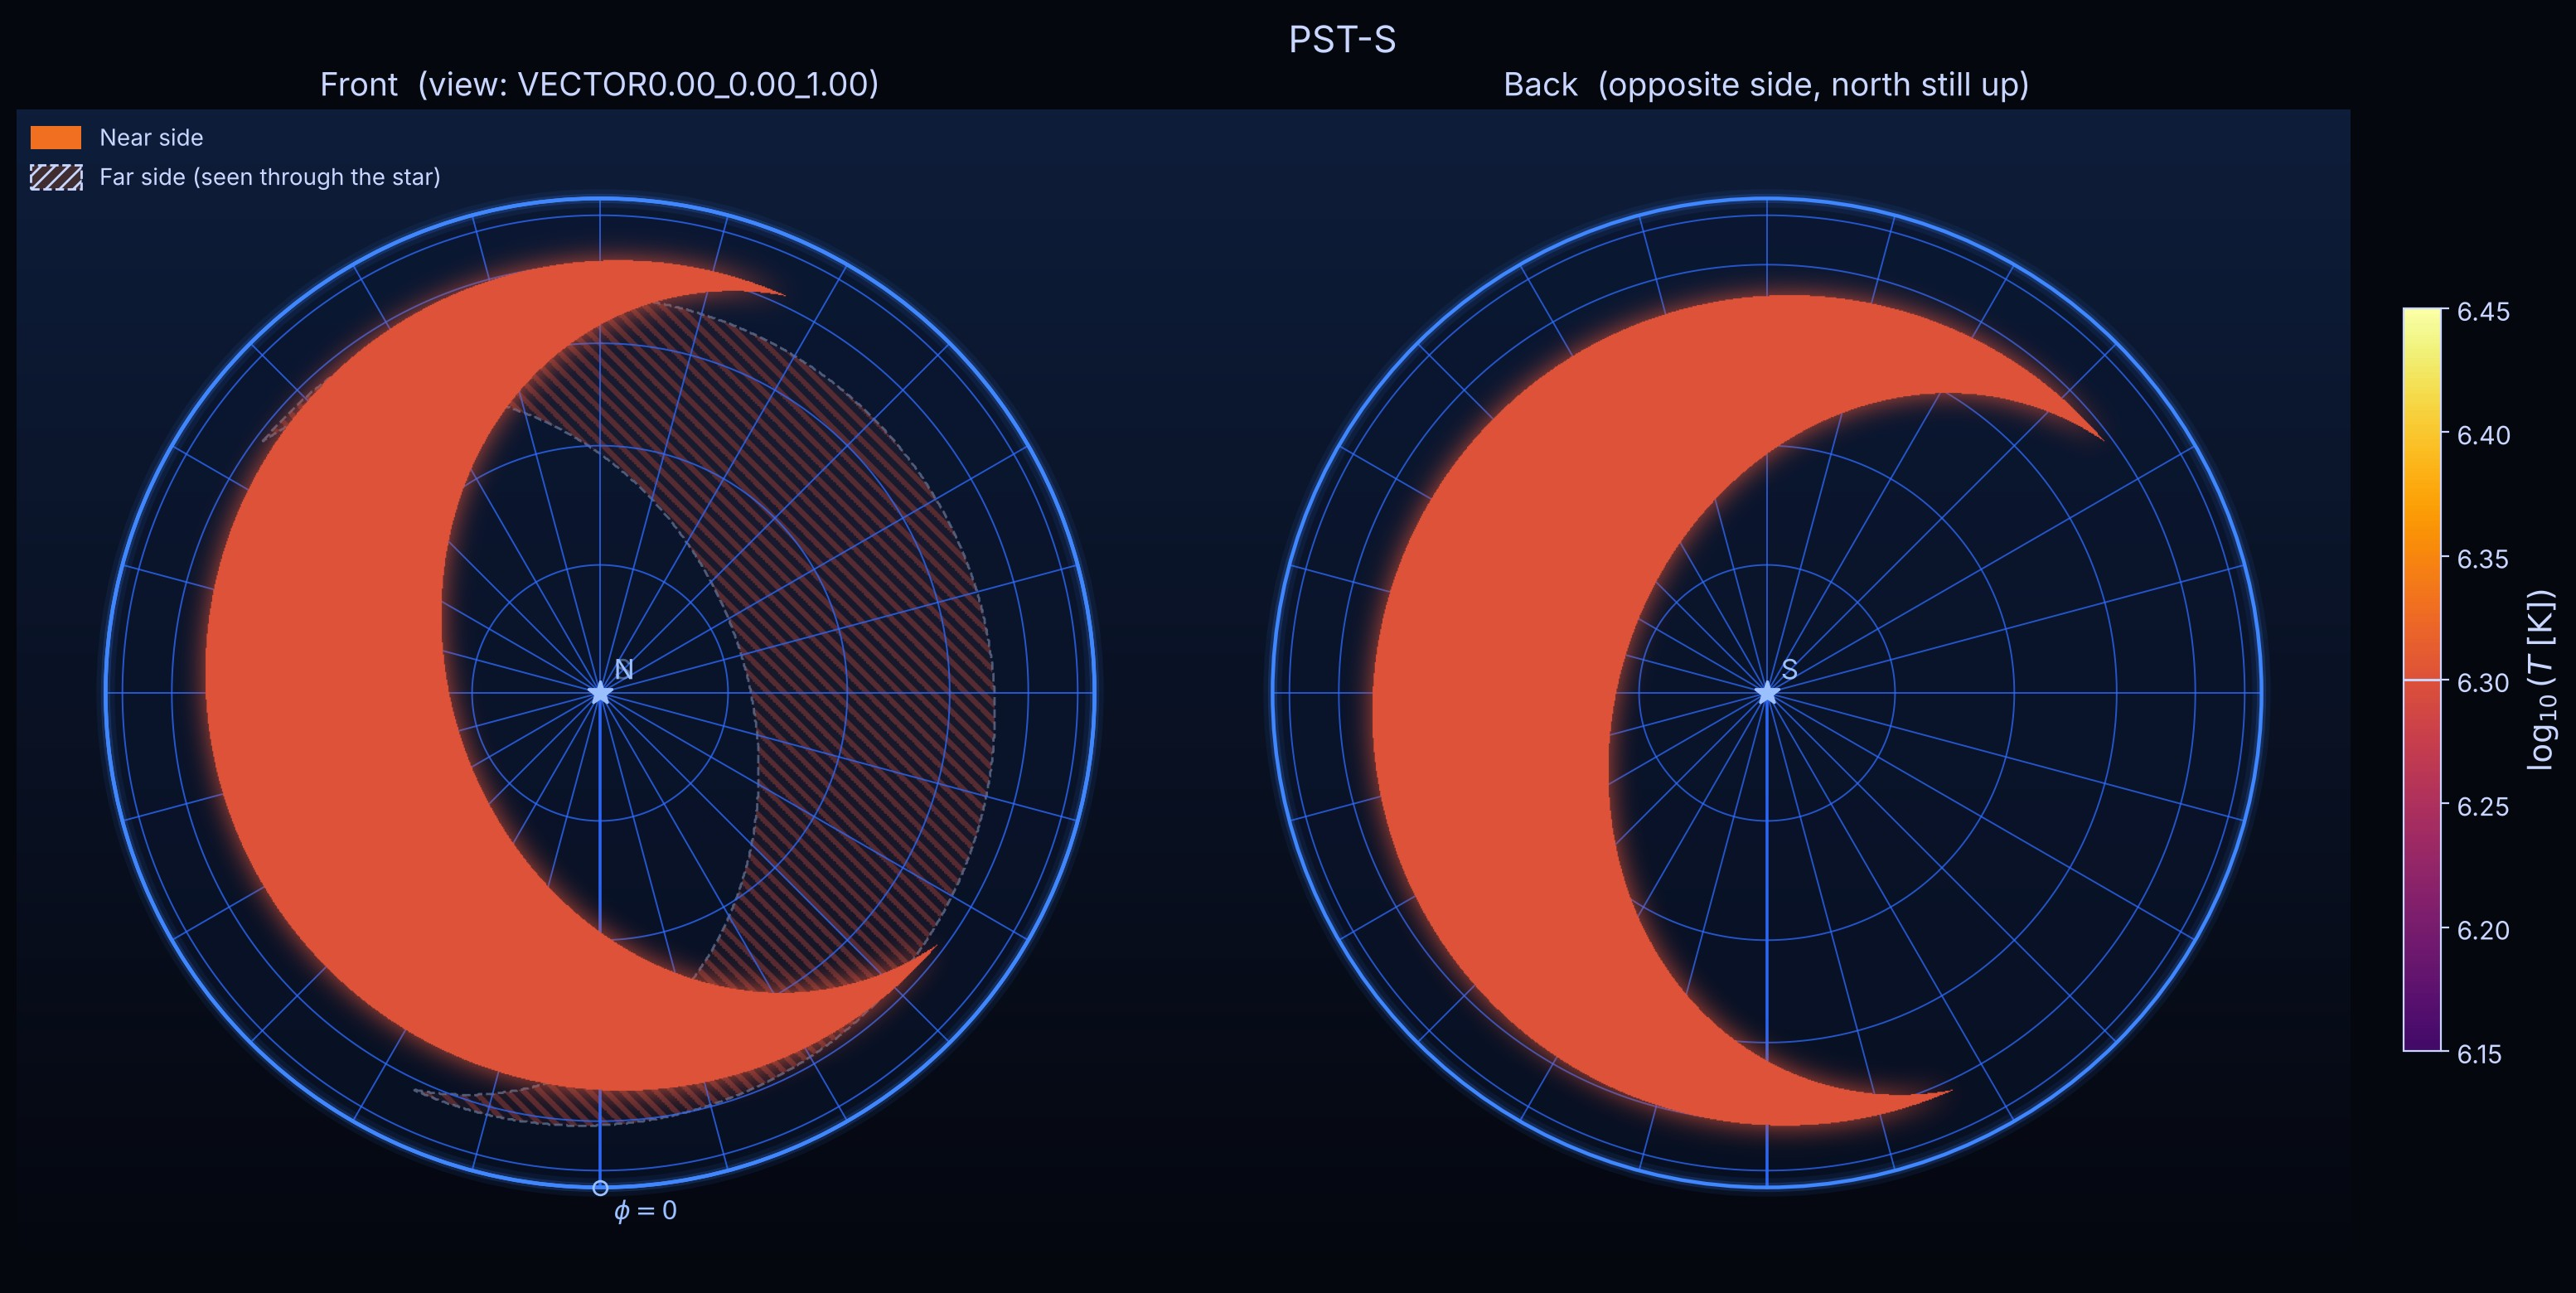

In [20]:
plot_projection_filled(P_dictionary_1hsPST, "PST-S", [0, 0, 1], back_view=True);

### 2.3) Same type of hot region: antipodal with free size and temperature (`-Ua`)
The secondary is placed at the antipode of the primary, but its angular radius and temperature are separate parameters:

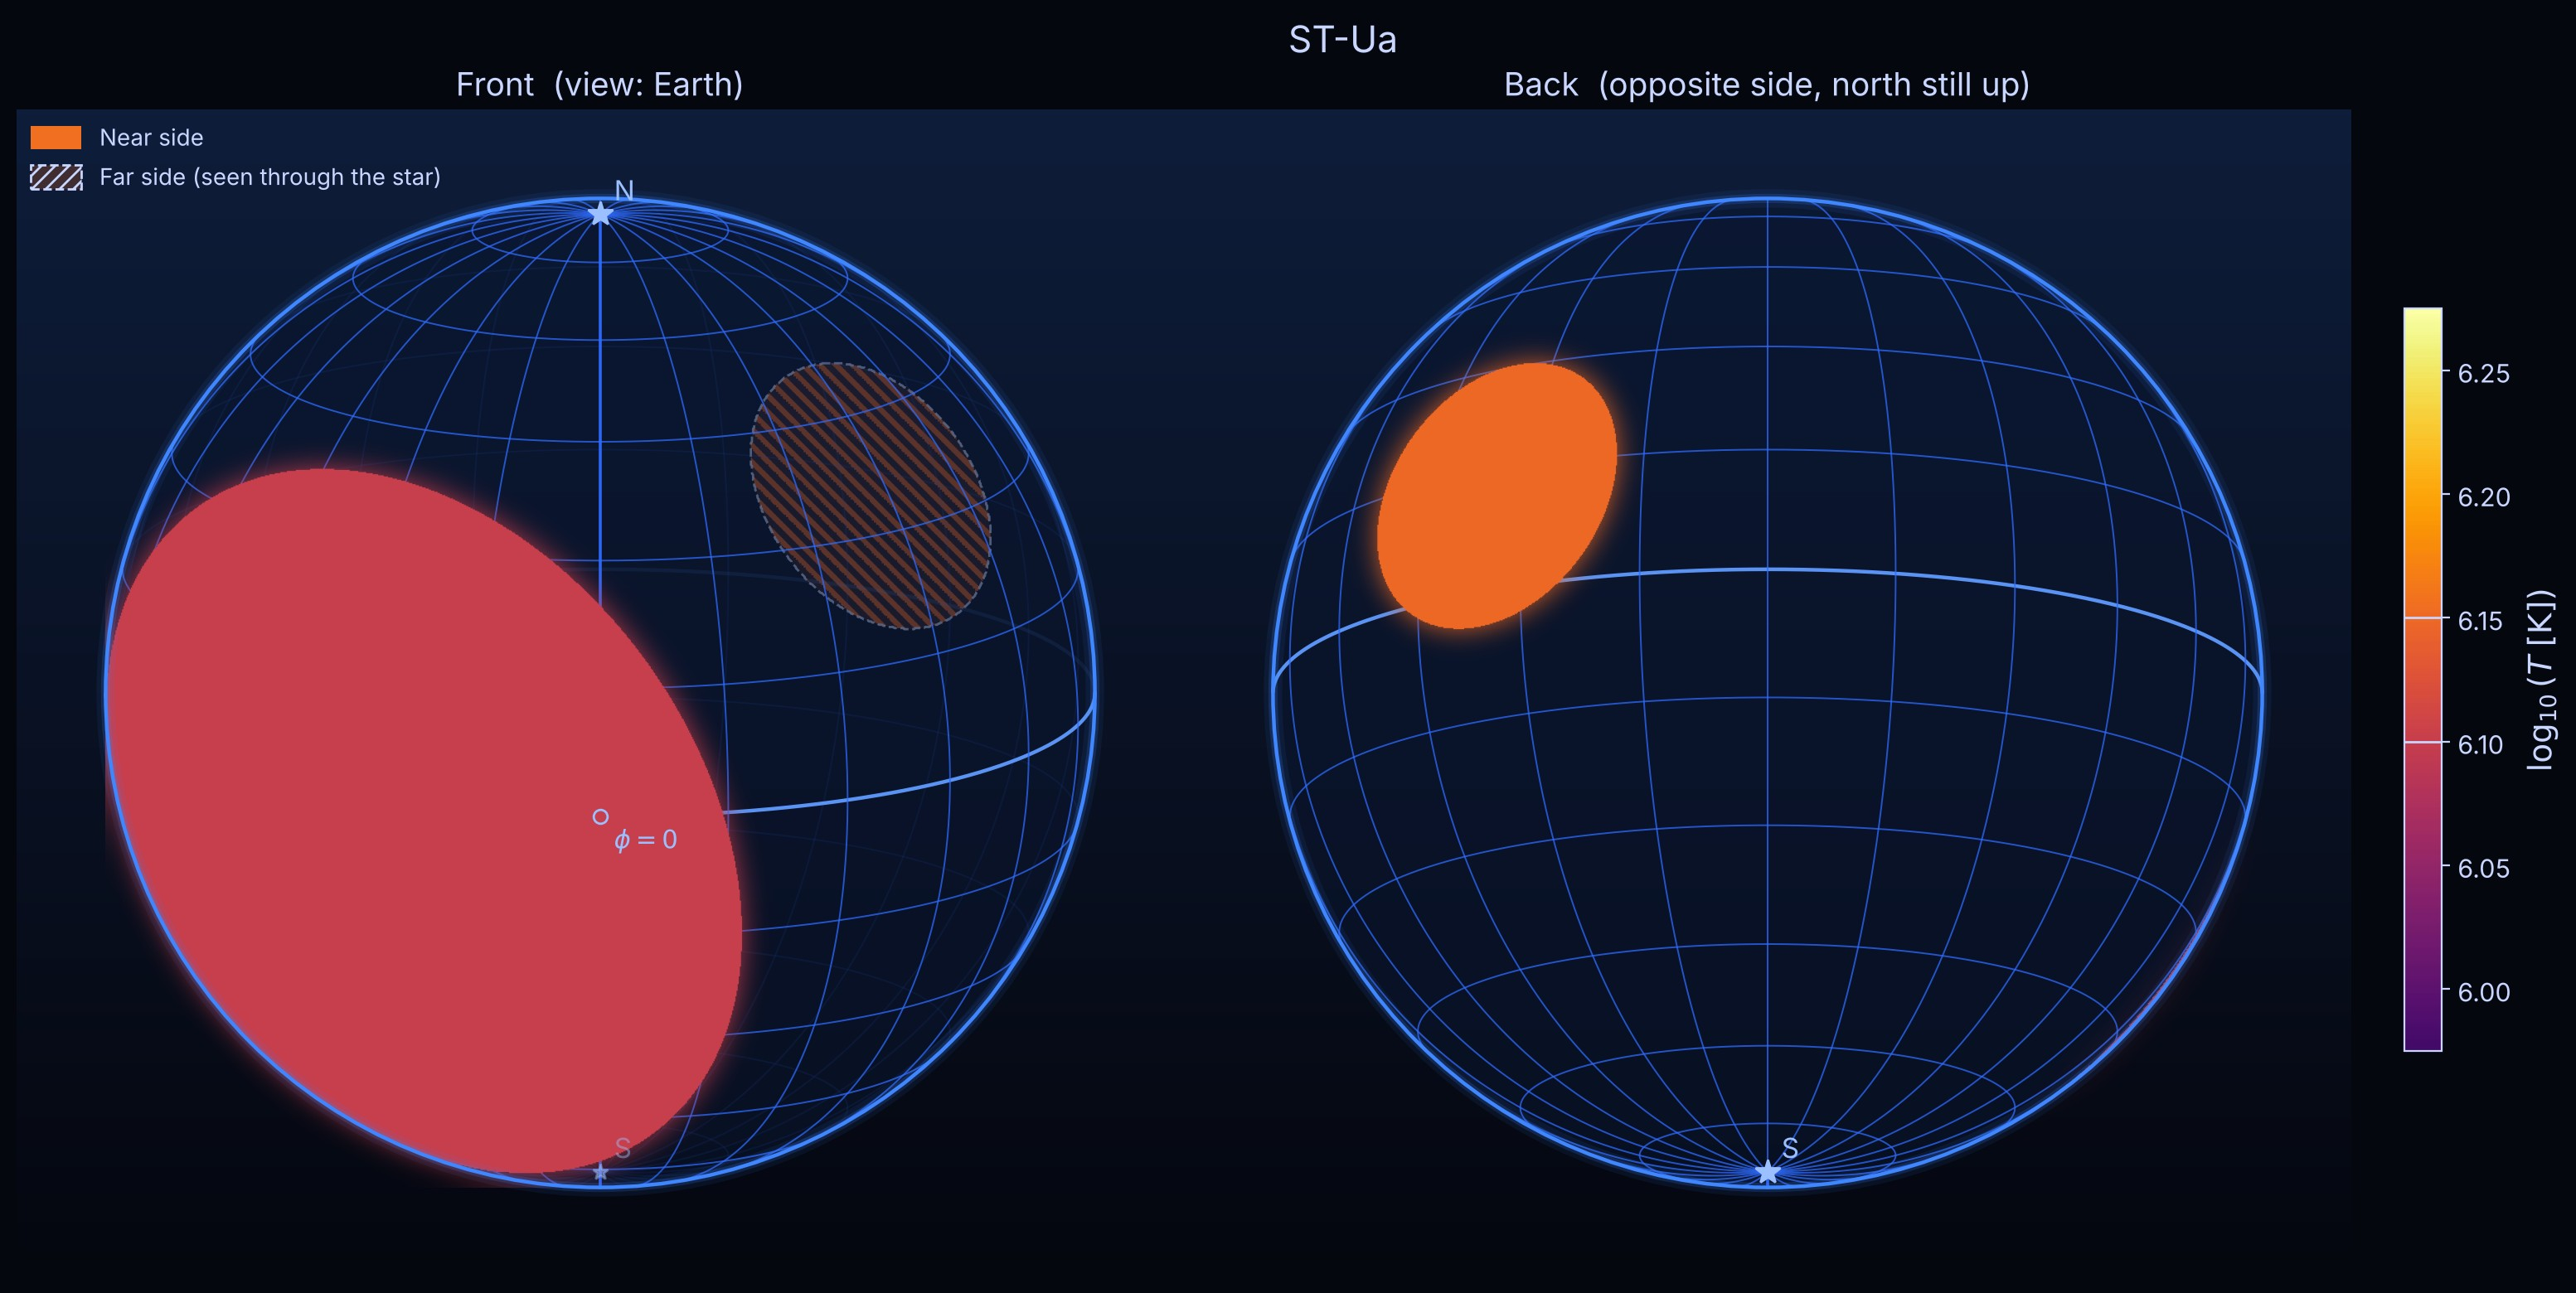

In [21]:
labels_2hsSTUa = ['mass', 'radius', 'cos_inclination',
                  's__super_radius', 's__super_temperature',
                  'p__phase_shift', 'p__super_colatitude', 'p__super_radius', 'p__super_temperature',
                  'beta', 'column_density']

values_2hsSTUa = [1.4, 15, 0.25, 0.3, 6.15, -0.1, 1.8, 0.9, 6.1, 9.3, 0.8]

P_dictionary_2hsSTUa = dict(zip(labels_2hsSTUa, values_2hsSTUa))
plot_projection_filled(P_dictionary_2hsSTUa, "ST-Ua", "I", back_view=True);

### 2.4) Same type of hot region: independent (`-U`)
`"ST-U"` is equivalent to `"ST+ST"`: both hot regions have their own parameters.

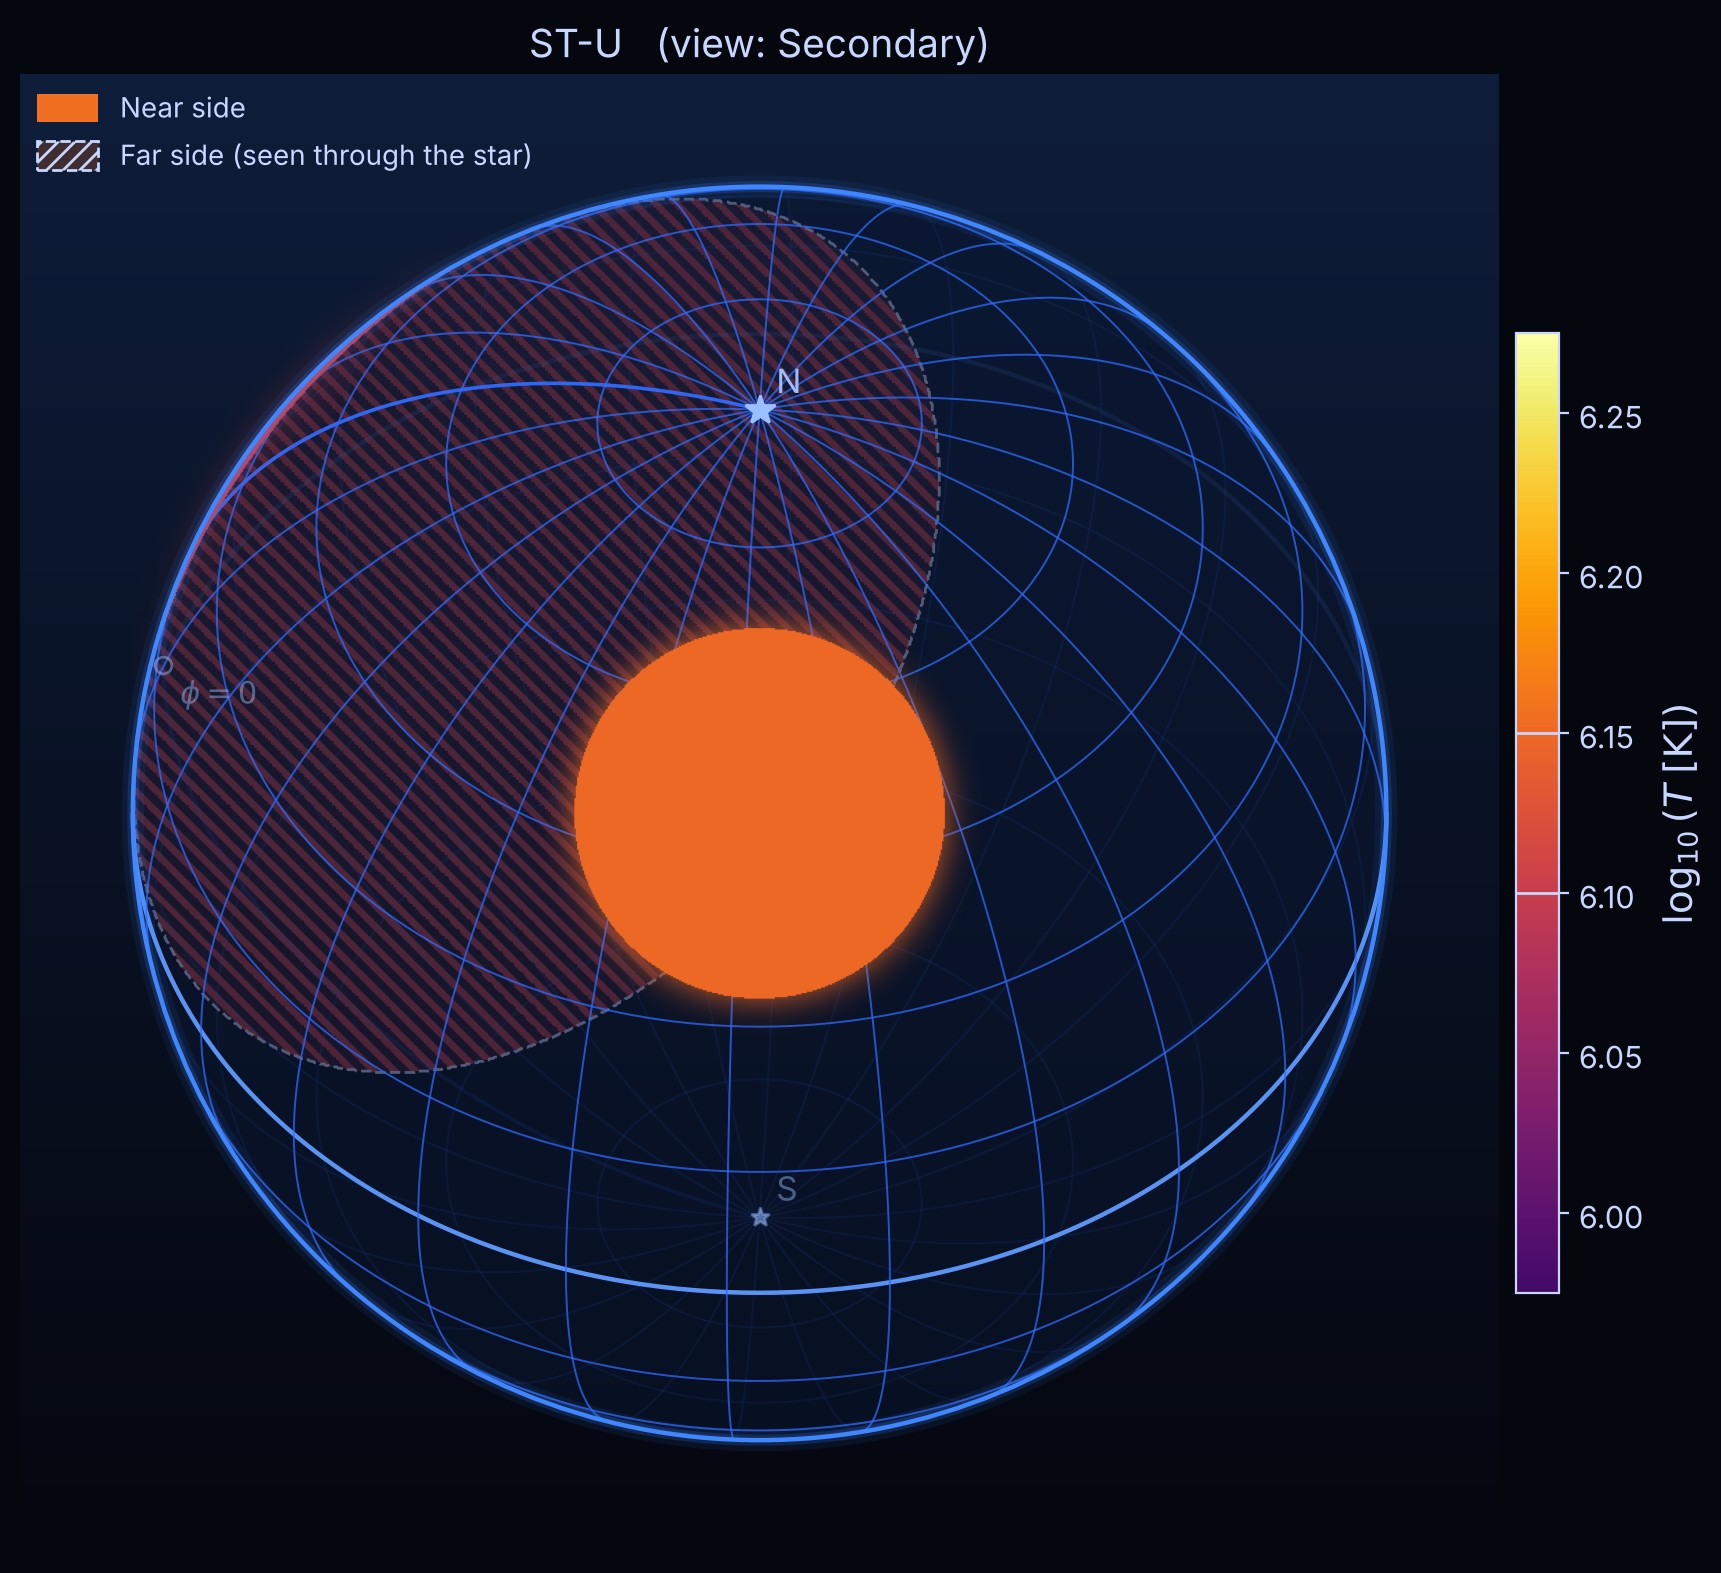

In [22]:
labels_2hsSTU = ['mass', 'radius', 'cos_inclination',
                 's__phase_shift', 's__super_colatitude', 's__super_radius', 's__super_temperature',
                 'p__phase_shift', 'p__super_colatitude', 'p__super_radius', 'p__super_temperature',
                 'beta', 'column_density']

values_2hsSTU = [1.4, 15, 0.25, 0.3, 0.7, 0.3, 6.15, -0.1, 1.8, 0.9, 6.1, 9.3, 0.8]

P_dictionary_2hsSTU = dict(zip(labels_2hsSTU, values_2hsSTU))
plot_projection_filled(P_dictionary_2hsSTU, "ST-U", "S");

## 3) Styles and colormaps
For papers, the light style may work better (it uses the full `inferno` colormap by default). Several panels can be combined by passing `ax`:

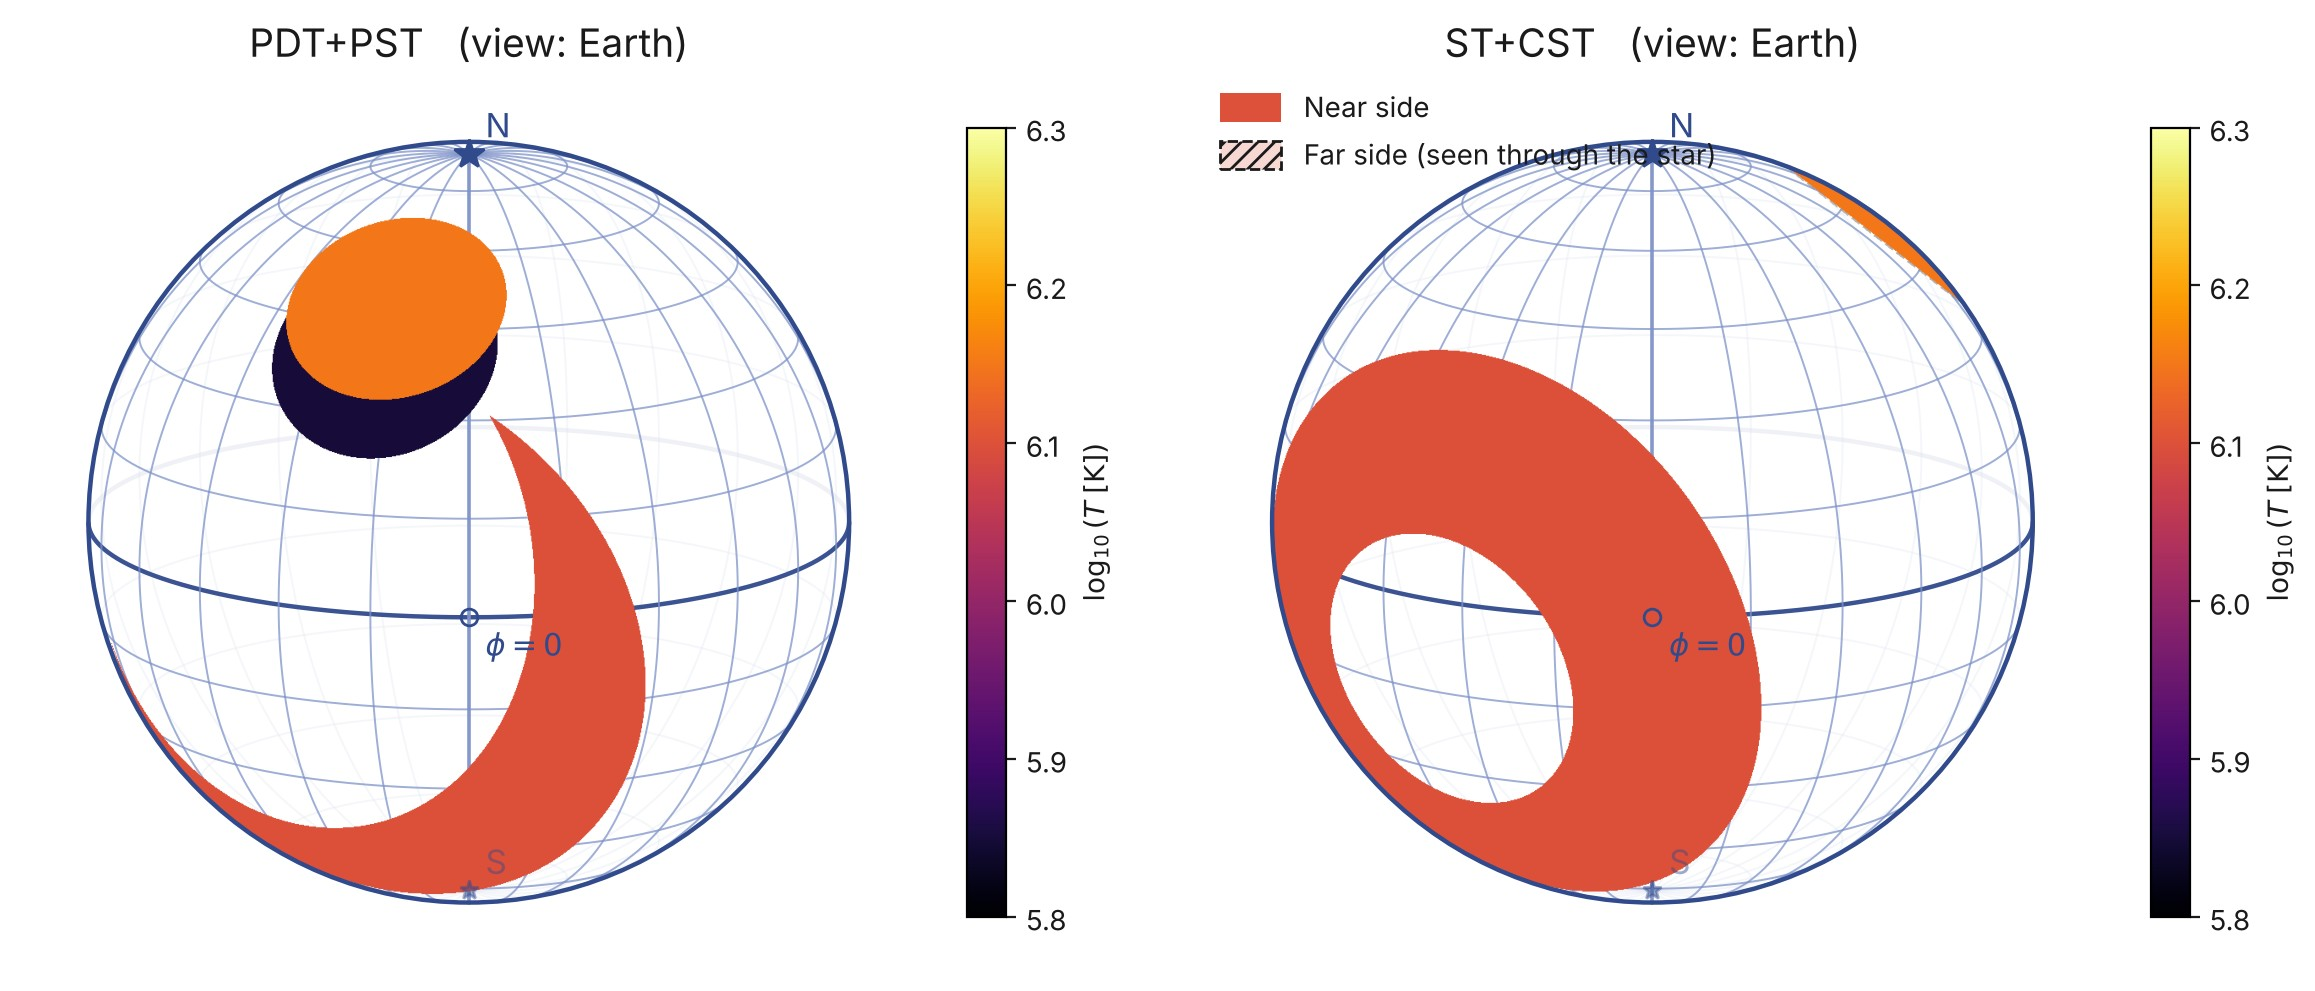

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
plot_projection_filled(P_dictionary_2hsPDTPST, "PDT+PST", "I", style="light",
                       Tmin=5.8, Tmax=6.3, ax=axes[0])
plot_projection_filled(P_dictionary_2hsSTCST, "ST+CST", "I", style="light",
                       Tmin=5.8, Tmax=6.3, ax=axes[1]);

Any matplotlib colormap can be passed with `cmap`. An orange-to-magenta colormap, `HOT_GLOW_CMAP`, is also provided:

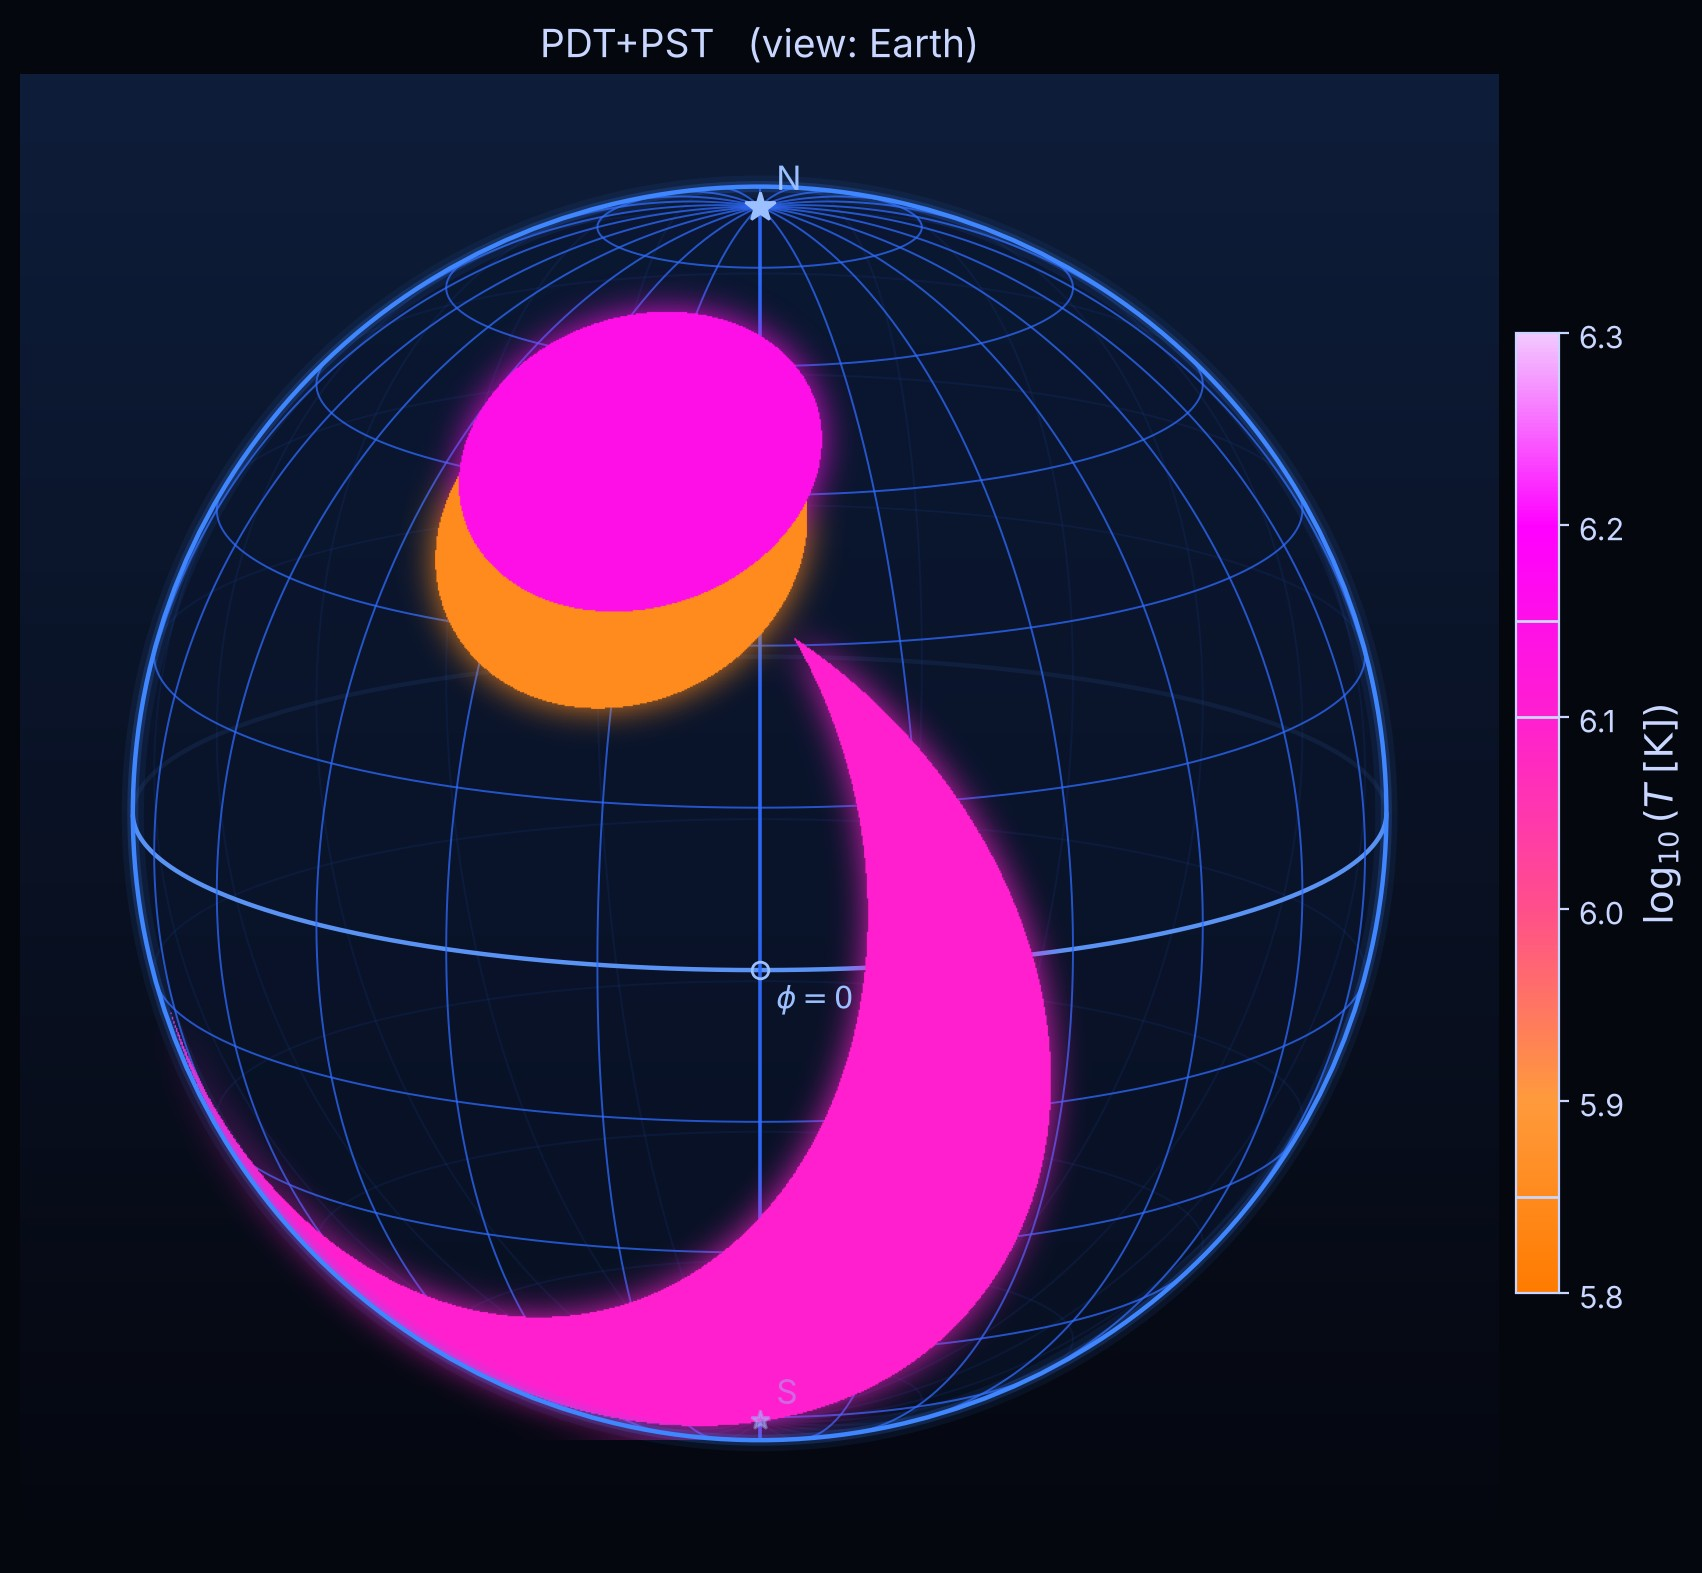

In [24]:
plot_projection_filled(P_dictionary_2hsPDTPST, "PDT+PST", "I", Tmin=5.8, Tmax=6.3, cmap=HOT_GLOW_CMAP);

## 4) Movies of the star rotating
`animate_projection_filled` writes a movie of the star spinning, as seen by the observer. The observer stays at colatitude `arccos(cos_inclination)` (or `inclination`, in radians, if you pass it) and the star rotates prograde about its north pole, which stays at the top of the frame.

The phase shown in the title follows the X-PSI convention: a hot region with `phase_shift` $= s$ crosses the observer's meridian at phase $-s$ (mod 1), as in X-PSI pulse profiles. There, light bending, time delays and Doppler boosting shift features slightly; this projection ignores them.

The file type is set by the file name:
<ul>
  <li>**`.mp4`** (H.264): small files that play everywhere. This needs `ffmpeg` to be installed, e.g. with `conda install ffmpeg`.</li>
  <li>**`.gif`**: written with Pillow, so no extra software is needed, and it plays inline almost anywhere (GitHub, slides, web pages). The files are larger, so use fewer frames or a lower resolution.</li>
</ul>

Other options: `n_frames`, `fps`, `n_rotations` (the movie loops seamlessly), `dpi` (frame size), `crf` (MP4 quality: lower is better but gives a larger file) and `show_phase`. Any other keyword arguments (`Tmin`, `Tmax`, `cmap`, `style`, `show_outlines`, `far_style`, `resolution`, ...) are passed on to `plot_projection_filled`, and the colour scale is the same in every frame.

In [25]:
animate_projection_filled(P_dictionary_2hsPDTPST, "PDT+PST", "rotation_PDT_PST.mp4",
                          n_frames=72, fps=24, Tmin=5.8, Tmax=6.3, dpi=70)

from IPython.display import Video
Video("rotation_PDT_PST.mp4", embed=True, html_attributes="controls loop autoplay muted")

If the movie doesn't play when you open this notebook in Jupyter (you see an empty player or a loading wheel), Jupyter doesn't trust the notebook's saved outputs yet. Run `jupyter trust Emitting_patterns_2Dprojection.ipynb` in a terminal and reload the page, or re-run the cell above.

The same movie as a GIF, at a lower resolution to keep the file small:

In [26]:
# animate_projection_filled(P_dictionary_2hsPDTPST, "PDT+PST", "rotation_PDT_PST.gif",
#                           n_frames=48, fps=16, Tmin=5.8, Tmax=6.3, resolution=400, dpi=50)

## Notes
<ul>
  <li>The warnings printed by this tool do not cover all the checks X-PSI itself makes. For example, they don't check that a region declared eccentric (`E`) really is eccentric rather than protruding. They do warn when a concentric configuration masks one component completely.</li>
  <li>If two <i>different</i> hot regions overlap, X-PSI simply adds their signals. The plot shows the hotter one and prints a warning.</li>
  <li>For a 3-vector point of view that isn't unit length, the vector is normalised and a warning is printed.</li>
</ul>